# VideoMamba Tiny — IPN-Hand Evaluation + VideoMAE ViT-L/16 Complexity Comparison

Clean Kaggle notebook for three independent tasks:

1. **Isolated gesture classification** on the IPN-Hand test annotations.
2. **Continuous gesture recognition** with configurable sliding-window overlap and explicit post-processing.
3. **Architecture complexity comparison**:
   - VideoMamba-Tiny
   - VideoMAE v1 ViT-L/16
   - VideoMAE v2 ViT-L/16

The complexity section is intentionally independent from continuous-video evaluation.

### Minimal cells for Params / GFLOPs only
Run Sections **0 → 1 → 3 → 6**. Dataset annotation loading and continuous evaluation are not required for architecture complexity.

### Default continuous configuration
- `WINDOW_SIZE = 64`
- `WINDOW_STEP = 16` → **75% overlap**
- `MODEL_FRAMES = 16`

The post-processing defaults are kept at the previous baseline so overlap can be changed as a single experimental variable. A short-gesture-safe preset is included as comments in the configuration cell.


## 0. Runtime setup

This section prepares VideoMamba and its dependencies. The notebook first provides a PyTorch-reference fallback so model construction is robust. If the prebuilt CUDA wheels used by the previous notebook are available, Section 3 activates the native CUDA Mamba kernels before evaluation/latency benchmarking.


In [1]:
import os
import sys
import subprocess
from pathlib import Path

# Core Python packages.
packages = [
    "timm",
    "einops",
    "transformers",
    "opencv-python-headless",
    "matplotlib",
    "pandas",
    "numpy",
    "torchvision",
    "tqdm",
    "scikit-learn",
]
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", *packages],
    check=True,
)

VIDEOMAMBA_REPO = Path("/kaggle/working/VideoMamba")
MAMBA_ROOT = VIDEOMAMBA_REPO / "mamba"
MAMBA_PACKAGE_DIR = MAMBA_ROOT / "mamba_ssm"
VIDEOMAMBA_PATH = VIDEOMAMBA_REPO / "videomamba" / "video_sm"

if not VIDEOMAMBA_REPO.exists():
    print("Cloning OpenGVLab/VideoMamba ...")
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/OpenGVLab/VideoMamba.git",
         str(VIDEOMAMBA_REPO)],
        check=True,
    )
else:
    print("VideoMamba already exists:", VIDEOMAMBA_REPO)

assert MAMBA_PACKAGE_DIR.is_dir(), MAMBA_PACKAGE_DIR
assert VIDEOMAMBA_PATH.is_dir(), VIDEOMAMBA_PATH

for p in [str(VIDEOMAMBA_PATH), str(MAMBA_ROOT)]:
    while p in sys.path:
        sys.path.remove(p)
    sys.path.insert(0, p)

print("MAMBA_ROOT      :", MAMBA_ROOT)
print("VIDEOMAMBA_PATH:", VIDEOMAMBA_PATH)


Cloning OpenGVLab/VideoMamba ...


Cloning into '/kaggle/working/VideoMamba'...


MAMBA_ROOT      : /kaggle/working/VideoMamba/mamba
VIDEOMAMBA_PATH: /kaggle/working/VideoMamba/videomamba/video_sm


In [2]:
import types
import random
import importlib
import importlib.machinery

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from einops import rearrange, repeat
from torchvision import transforms
from IPython.display import display
from tqdm.auto import tqdm

# -------------------------------------------------------------------------
# Clean previous Mamba imports so this cell can be rerun.
# -------------------------------------------------------------------------
for name in list(sys.modules):
    if name == "mamba_ssm" or name.startswith("mamba_ssm."):
        del sys.modules[name]

for name in ["causal_conv1d", "causal_conv1d_cuda", "selective_scan_cuda"]:
    sys.modules.pop(name, None)

importlib.invalidate_caches()

# -------------------------------------------------------------------------
# Source-package namespace.
# -------------------------------------------------------------------------
mamba_pkg = types.ModuleType("mamba_ssm")
mamba_pkg.__file__ = str(MAMBA_PACKAGE_DIR / "__init__.py")
mamba_pkg.__path__ = [str(MAMBA_PACKAGE_DIR)]
mamba_pkg.__package__ = "mamba_ssm"

mamba_spec = importlib.machinery.ModuleSpec(
    name="mamba_ssm",
    loader=None,
    is_package=True,
)
mamba_spec.submodule_search_locations = [str(MAMBA_PACKAGE_DIR)]
mamba_pkg.__spec__ = mamba_spec
sys.modules["mamba_ssm"] = mamba_pkg

# -------------------------------------------------------------------------
# PyTorch fallback for causal_conv1d.
# -------------------------------------------------------------------------
causal_mod = types.ModuleType("causal_conv1d")

def causal_conv1d_fn(x, weight, bias=None, activation=None):
    seqlen = x.shape[-1]
    dim = x.shape[1]
    width = weight.shape[-1]

    if weight.ndim == 2:
        w = weight.unsqueeze(1)
    elif weight.ndim == 3:
        w = weight
    else:
        raise ValueError(f"Invalid causal_conv1d weight shape: {tuple(weight.shape)}")

    out = F.conv1d(
        x,
        w,
        bias=bias,
        padding=width - 1,
        groups=dim,
    )[..., :seqlen]

    if activation in ["silu", "swish"]:
        out = F.silu(out)
    return out

def causal_conv1d_update(*args, **kwargs):
    raise NotImplementedError(
        "causal_conv1d_update is not used in batch VideoMamba inference."
    )

causal_mod.causal_conv1d_fn = causal_conv1d_fn
causal_mod.causal_conv1d_update = causal_conv1d_update
sys.modules["causal_conv1d"] = causal_mod
sys.modules["causal_conv1d_cuda"] = types.ModuleType("causal_conv1d_cuda")
sys.modules["selective_scan_cuda"] = types.ModuleType("selective_scan_cuda")

# -------------------------------------------------------------------------
# PyTorch fallback for RMSNorm/Triton layernorm.
# -------------------------------------------------------------------------
class RMSNorm(nn.Module):
    def __init__(self, d_model, eps=1e-5, device=None, dtype=None):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d_model, device=device, dtype=dtype))
        self.register_parameter("bias", None)

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def rms_norm_fn(
    x,
    weight,
    bias=None,
    residual=None,
    eps=1e-5,
    prenorm=False,
    residual_in_fp32=False,
):
    if residual is not None:
        if residual_in_fp32:
            residual = residual.float()
        x = x + residual
        res = x
    else:
        res = x

    normed = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + eps) * weight
    if bias is not None:
        normed = normed + bias

    if prenorm:
        return normed, res
    return normed

triton_ln = types.ModuleType("mamba_ssm.ops.triton.layernorm")
triton_ln.RMSNorm = RMSNorm
triton_ln.layer_norm_fn = None
triton_ln.rms_norm_fn = rms_norm_fn
sys.modules["mamba_ssm.ops.triton.layernorm"] = triton_ln

# Compatibility shim for some transformers versions.
try:
    import transformers.generation
    if not hasattr(transformers.generation, "GreedySearchDecoderOnlyOutput"):
        transformers.generation.GreedySearchDecoderOnlyOutput = object
        transformers.generation.SampleDecoderOnlyOutput = object
except Exception:
    pass

import mamba_ssm.ops.selective_scan_interface as ssi
import mamba_ssm.modules.mamba_simple as ms

def mamba_inner_fn_no_out_proj(
    xz,
    conv1d_weight,
    conv1d_bias,
    x_proj_weight,
    delta_proj_weight,
    A,
    B=None,
    C=None,
    D=None,
    delta_bias=None,
    B_proj_bias=None,
    C_proj_bias=None,
    delta_softplus=True,
):
    L = xz.shape[-1]
    delta_rank = delta_proj_weight.shape[1]
    d_state = A.shape[-1] * (1 if not A.is_complex() else 2)

    x, z = xz.chunk(2, dim=1)

    x = causal_conv1d_fn(
        x,
        rearrange(conv1d_weight, "d 1 w -> d w"),
        conv1d_bias,
        "silu",
    )

    x_dbl = F.linear(
        rearrange(x, "b d l -> (b l) d"),
        x_proj_weight,
    )

    delta = delta_proj_weight @ x_dbl[:, :delta_rank].t()
    delta = rearrange(delta, "d (b l) -> b d l", l=L)

    if B is None:
        B = x_dbl[:, delta_rank:delta_rank + d_state]
        if B_proj_bias is not None:
            B = B + B_proj_bias.to(dtype=B.dtype)
        if not A.is_complex():
            B = rearrange(B, "(b l) dstate -> b dstate l", l=L).contiguous()
        else:
            B = rearrange(
                B, "(b l) (dstate two) -> b dstate (l two)",
                l=L, two=2
            ).contiguous()

    if C is None:
        C = x_dbl[:, -d_state:]
        if C_proj_bias is not None:
            C = C + C_proj_bias.to(dtype=C.dtype)
        if not A.is_complex():
            C = rearrange(C, "(b l) dstate -> b dstate l", l=L).contiguous()
        else:
            C = rearrange(
                C, "(b l) (dstate two) -> b dstate (l two)",
                l=L, two=2
            ).contiguous()

    return ssi.selective_scan_ref(
        x,
        delta,
        A,
        B,
        C,
        D,
        z=z,
        delta_bias=delta_bias,
        delta_softplus=delta_softplus,
    )

# Reference implementation for robust model loading.
ssi.selective_scan_fn = ssi.selective_scan_ref
ssi.mamba_inner_fn = ssi.mamba_inner_ref
ssi.bimamba_inner_fn = ssi.bimamba_inner_ref
ssi.mamba_inner_fn_no_out_proj = mamba_inner_fn_no_out_proj

ms.selective_scan_fn = ssi.selective_scan_ref
ms.mamba_inner_fn = ssi.mamba_inner_ref
ms.bimamba_inner_fn = ssi.bimamba_inner_ref
ms.mamba_inner_fn_no_out_proj = mamba_inner_fn_no_out_proj

from models import videomamba_tiny

MAMBA_BACKEND = "pytorch_reference"

print("OpenCV         :", cv2.__version__)
print("PyTorch        :", torch.__version__)
print("CUDA available :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU            :", torch.cuda.get_device_name(0))
print("VideoMamba     : imported")
print("Mamba backend  :", MAMBA_BACKEND)


/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:158: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:227: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:295: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:368: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interf

OpenCV         : 4.13.0
PyTorch        : 2.10.0+cu128
CUDA available : True
GPU            : Tesla T4
VideoMamba     : imported
Mamba backend  : pytorch_reference


## 1. Global configuration

All experiment-changing parameters are centralized here. There is no hard-coded assumption that overlap must equal 50%.


In [3]:
from pathlib import Path

# ---------------------------------------------------------------------
# Kaggle inputs
# ---------------------------------------------------------------------
DATASET_ROOT = Path("/kaggle/input/datasets/soumicksarker/ipn-hand-dataset")
ANNOT_DIR = DATASET_ROOT / "annotations" / "annotations"
DATASET_VIDEOS_DIR = DATASET_ROOT / "videos" / "videos"

ANNOT_ALL_PATH = ANNOT_DIR / "Annot_List.txt"
ANNOT_TRAIN_PATH = ANNOT_DIR / "Annot_TrainList.txt"
ANNOT_TEST_PATH = ANNOT_DIR / "Annot_TestList.txt"

CHECKPOINT_PATH = Path(
    "/kaggle/input/models/hoanganh94/"
    "bestcheckpoint/pytorch/default/1/checkpoint-best.pth"
)

# Prebuilt CUDA wheels from the previous working Kaggle setup.
ACTIVATE_NATIVE_MAMBA_CUDA = True
WHEEL_DIR = Path("/kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels")
CAUSAL_WHEEL = WHEEL_DIR / "causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl"
MAMBA_WHEEL = WHEEL_DIR / "mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl"

# ---------------------------------------------------------------------
# Model
# ---------------------------------------------------------------------
NUM_FRAMES = 16
IMG_SIZE = 224
NUM_CLASSES = 14
LOAD_IPN_CHECKPOINT = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Strict FP32 policy.
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    try:
        torch.set_float32_matmul_precision("highest")
    except Exception:
        pass

# ---------------------------------------------------------------------
# Continuous recognition
# ---------------------------------------------------------------------
CONTINUOUS_VIDEO = "1CM1_2_R__224.avi"

WINDOW_SIZE = 64
WINDOW_STEP = 16              # 75% overlap
MODEL_FRAMES = NUM_FRAMES

ENABLE_SMOOTHING = False

# Baseline post-processing values from the previous notebook.
# Keep these while testing overlap as the only changed variable.
T_AVG_SEC = 2.0
MIN_GESTURE_SEC = 1.2
FILL_SAME_NEIGHBORS = True

# Evaluation tolerance only; it does NOT modify predictions.
THETA_SEC = 2.0

# Short-gesture-safe preset to test later as a separate experiment:
# T_AVG_SEC = 0.3
# MIN_GESTURE_SEC = 0.5
# FILL_SAME_NEIGHBORS = False

assert MODEL_FRAMES == 16
assert 0 < WINDOW_STEP <= WINDOW_SIZE
assert WINDOW_SIZE % MODEL_FRAMES == 0, (
    "WINDOW_SIZE must be divisible by MODEL_FRAMES for fixed-stride sampling."
)

OVERLAP_RATIO = 1.0 - WINDOW_STEP / WINDOW_SIZE

print("DEVICE          :", DEVICE)
print("Window size     :", WINDOW_SIZE)
print("Window step     :", WINDOW_STEP)
print("Window overlap  :", f"{OVERLAP_RATIO*100:.2f}%")
print("Model frames    :", MODEL_FRAMES)
print("T_AVG_SEC       :", T_AVG_SEC, "(post-processing)")
print("MIN_GESTURE_SEC :", MIN_GESTURE_SEC, "(post-processing)")
print("THETA_SEC       :", THETA_SEC, "(evaluation only)")


DEVICE          : cuda
Window size     : 64
Window step     : 16
Window overlap  : 75.00%
Model frames    : 16
T_AVG_SEC       : 2.0 (post-processing)
MIN_GESTURE_SEC : 1.2 (post-processing)
THETA_SEC       : 2.0 (evaluation only)


## 2. Dataset and annotations

This section is needed for isolated/continuous IPN-Hand evaluation. It is **not required** for architecture-only Params/GFLOPs benchmarking.


In [4]:
import re

CLASS_CODES = [
    "D0X", "B0A", "B0B",
    "G01", "G02", "G03", "G04", "G05", "G06",
    "G07", "G08", "G09", "G10", "G11",
]

CLASS_DESCRIPTIONS = [
    "No gesture",
    "Pointing with one finger",
    "Pointing with two fingers",
    "Click with one finger",
    "Click with two fingers",
    "Throw up",
    "Throw down",
    "Throw left",
    "Throw right",
    "Open twice",
    "Double click with one finger",
    "Double click with two fingers",
    "Zoom in",
    "Zoom out",
]

CLASS_NAMES = [
    f"{code} - {desc}"
    for code, desc in zip(CLASS_CODES, CLASS_DESCRIPTIONS)
]

required_dataset_paths = {
    "video dir": DATASET_VIDEOS_DIR,
    "Annot_List": ANNOT_ALL_PATH,
    "Annot_TrainList": ANNOT_TRAIN_PATH,
    "Annot_TestList": ANNOT_TEST_PATH,
}

for name, p in required_dataset_paths.items():
    print(f"{name:18s}: {p} -> {p.exists()}")

assert DATASET_VIDEOS_DIR.is_dir(), (
    "Attach the IPN-Hand Kaggle dataset before running evaluation sections."
)
assert ANNOT_TEST_PATH.is_file(), ANNOT_TEST_PATH

def canonical_video_key(name):
    name = Path(str(name).strip()).stem.lower()
    return re.sub(r"[^a-z0-9]", "", name)

VIDEO_INDEX = {
    canonical_video_key(p.name): p
    for p in DATASET_VIDEOS_DIR.glob("*.avi")
}

def resolve_video_path(video_name):
    return VIDEO_INDEX.get(canonical_video_key(video_name), None)

def read_ipn_annotations(path):
    raw = pd.read_csv(
        path,
        sep=",",
        header=None,
        dtype=str,
        engine="python",
    )

    if raw.shape[1] < 5:
        raise ValueError(
            f"{path.name} has {raw.shape[1]} columns; at least 5 are required."
        )

    df = raw.iloc[:, :5].copy()
    df.columns = ["video", "label", "id", "t_start", "t_end"]

    for col in ["video", "label"]:
        df[col] = df[col].astype(str).str.strip()

    for col in ["id", "t_start", "t_end"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(subset=["id", "t_start", "t_end"]).copy()
    df["id"] = df["id"].astype(int)
    df["t_start"] = df["t_start"].astype(int)
    df["t_end"] = df["t_end"].astype(int)
    df = df[df["id"].between(1, NUM_CLASSES)].copy()

    df["video_path"] = df["video"].apply(resolve_video_path)
    df["video_found"] = df["video_path"].notna()
    df["class_idx"] = df["id"] - 1
    df["class_code"] = df["class_idx"].map(CLASS_CODES.__getitem__)

    return df.reset_index(drop=True)

df_all = read_ipn_annotations(ANNOT_ALL_PATH)
df_train = read_ipn_annotations(ANNOT_TRAIN_PATH)
df_test = read_ipn_annotations(ANNOT_TEST_PATH)

summary = pd.DataFrame({
    "split": ["all", "train", "test"],
    "annotations": [len(df_all), len(df_train), len(df_test)],
    "mapped": [
        int(df_all["video_found"].sum()),
        int(df_train["video_found"].sum()),
        int(df_test["video_found"].sum()),
    ],
})
display(summary)

unmatched = df_all.loc[~df_all["video_found"], "video"].drop_duplicates()
if len(unmatched):
    print("Unmatched example:", unmatched.head(10).tolist())

print("AVI files:", len(VIDEO_INDEX))


video dir         : /kaggle/input/datasets/soumicksarker/ipn-hand-dataset/videos/videos -> True
Annot_List        : /kaggle/input/datasets/soumicksarker/ipn-hand-dataset/annotations/annotations/Annot_List.txt -> True
Annot_TrainList   : /kaggle/input/datasets/soumicksarker/ipn-hand-dataset/annotations/annotations/Annot_TrainList.txt -> True
Annot_TestList    : /kaggle/input/datasets/soumicksarker/ipn-hand-dataset/annotations/annotations/Annot_TestList.txt -> True


,split,annotations,mapped
0,all,5649,5649
1,train,4039,4039
2,test,1610,1610


AVI files: 200


## 3. VideoMamba model and common preprocessing

The model is first buildable with the reference fallback. If the prebuilt CUDA wheels are attached and compatible, this section reloads VideoMamba with native CUDA Mamba kernels. Architecture complexity does not depend on checkpoint weights, but evaluation requires the IPN-Hand checkpoint.


In [5]:
def load_videomamba_model(
    checkpoint_path=CHECKPOINT_PATH,
    num_classes=NUM_CLASSES,
    device=DEVICE,
    load_checkpoint=LOAD_IPN_CHECKPOINT,
):
    model_vm = videomamba_tiny(
        img_size=IMG_SIZE,
        num_frames=NUM_FRAMES,
        kernel_size=1,
        num_classes=num_classes,
    )

    checkpoint_loaded = False

    if load_checkpoint and Path(checkpoint_path).is_file():
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False,
        )
        state_dict = checkpoint.get("model", checkpoint)

        clean_state_dict = {}
        for k, v in state_dict.items():
            name = k[7:] if k.startswith("module.") else k
            clean_state_dict[name] = v

        model_vm.load_state_dict(clean_state_dict, strict=True)
        checkpoint_loaded = True
    elif load_checkpoint:
        print(
            "[WARNING] IPN-Hand checkpoint not found. "
            "Architecture benchmark can still run, but evaluation cannot."
        )

    model_vm = model_vm.float().to(device).eval()
    return model_vm, checkpoint_loaded


# First build using the robust reference import.
model, CHECKPOINT_LOADED = load_videomamba_model()

# -------------------------------------------------------------------------
# Optional native CUDA activation.
# -------------------------------------------------------------------------
if (
    ACTIVATE_NATIVE_MAMBA_CUDA
    and torch.cuda.is_available()
    and CAUSAL_WHEEL.is_file()
    and MAMBA_WHEEL.is_file()
):
    print("Installing prebuilt native Mamba CUDA wheels ...")

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "--force-reinstall",
            "--no-deps",
            str(CAUSAL_WHEEL),
            str(MAMBA_WHEEL),
        ],
        check=True,
    )

    for name in list(sys.modules):
        if (
            name == "mamba_ssm"
            or name.startswith("mamba_ssm.")
            or name == "causal_conv1d"
            or name.startswith("causal_conv1d.")
            or name == "causal_conv1d_cuda"
            or name == "selective_scan_cuda"
        ):
            sys.modules.pop(name, None)

    importlib.invalidate_caches()

    try:
        import causal_conv1d_cuda
        import selective_scan_cuda
        import mamba_ssm
        import mamba_ssm.ops.selective_scan_interface as ssi_native
        import mamba_ssm.modules.mamba_simple as ms_native

        ssi_native = importlib.reload(ssi_native)
        ms_native = importlib.reload(ms_native)

        if ssi_native.selective_scan_fn is ssi_native.selective_scan_ref:
            raise RuntimeError("Native selective_scan_fn still points to reference path.")

        import models.videomamba as vm_mod
        vm_mod.Mamba = ms_native.Mamba
        videomamba_tiny = vm_mod.videomamba_tiny

        model, CHECKPOINT_LOADED = load_videomamba_model()
        MAMBA_BACKEND = "native_cuda"

    except Exception as e:
        print("[WARNING] Native CUDA activation failed:", repr(e))
        print("Continuing with the already-built reference model.")
        MAMBA_BACKEND = "pytorch_reference"
else:
    print("Native CUDA wheels not activated; using reference backend.")

print("Checkpoint loaded:", CHECKPOINT_LOADED)
print("Mamba backend    :", MAMBA_BACKEND)
print("Model device     :", next(model.parameters()).device)
print("Model dtype      :", next(model.parameters()).dtype)


Use checkpoint: False
Checkpoint number: 0
Installing prebuilt native Mamba CUDA wheels ...


/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:158: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:227: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:295: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interface.py:368: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/kaggle/working/VideoMamba/mamba/mamba_ssm/ops/selective_scan_interf

Use checkpoint: False
Checkpoint number: 0
Checkpoint loaded: True
Mamba backend    : native_cuda
Model device     : cuda:0
Model dtype      : torch.float32


In [6]:
# ImageNet normalization used by the existing checkpoint pipeline.
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(IMG_SIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

def sample_indices(total_frames, num_frames=NUM_FRAMES):
    # Uniformly sample exactly num_frames over an isolated clip.
    if total_frames <= 0:
        return np.zeros(num_frames, dtype=np.int64)
    return np.linspace(
        0,
        total_frames - 1,
        num_frames,
    ).round().astype(np.int64)

def extract_frames_from_video(
    video_path,
    t_start=None,
    t_end=None,
    num_frames=NUM_FRAMES,
):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")

    total_vid_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # IPN-Hand annotations are 1-based.
    start_f = max(1, int(t_start)) if t_start is not None else 1
    end_f = (
        min(total_vid_frames, int(t_end))
        if t_end is not None
        else total_vid_frames
    )

    if end_f < start_f:
        cap.release()
        raise ValueError(f"Invalid frame range: {start_f} -> {end_f}")

    clip_len = end_f - start_f + 1
    sampled_rel_idx = sample_indices(clip_len, num_frames)
    sampled_abs_idx = start_f - 1 + sampled_rel_idx

    sampled_set = set(sampled_abs_idx.tolist())
    frames_dict = {}

    cap.set(cv2.CAP_PROP_POS_FRAMES, start_f - 1)
    curr_idx = start_f - 1

    while curr_idx <= end_f - 1 and len(frames_dict) < len(sampled_set):
        ok, frame = cap.read()
        if not ok:
            break
        if curr_idx in sampled_set:
            frames_dict[curr_idx] = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        curr_idx += 1

    cap.release()

    frames = []
    last_valid = None
    for idx in sampled_abs_idx:
        idx = int(idx)
        if idx in frames_dict:
            frame = frames_dict[idx]
            last_valid = frame
        elif last_valid is not None:
            frame = last_valid
        else:
            frame = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
        frames.append(frame)

    return np.asarray(frames), sampled_abs_idx + 1

def frames_to_tensor(frames_np, device=DEVICE):
    tensor = torch.stack([transform(frame) for frame in frames_np])
    tensor = tensor.permute(1, 0, 2, 3).unsqueeze(0).contiguous()
    return tensor.to(device=device, dtype=torch.float32, non_blocking=True)

def run_inference(model, frames_np, device=DEVICE):
    tensor = frames_to_tensor(frames_np, device)
    with torch.inference_mode():
        logits = model(tensor)
        probs = F.softmax(logits, dim=1).squeeze(0)

    probs = probs.detach().cpu().numpy()
    pred_idx = int(np.argmax(probs))
    confidence = float(probs[pred_idx])
    return pred_idx, confidence, probs


## 4. Isolated gesture classification

Each annotated gesture interval is treated as one isolated clip. Exactly 16 frames are uniformly sampled across the annotated interval. No sliding window or post-processing is used.


In [7]:
ISOLATED_INCLUDE_NO_GESTURE = False
ISOLATED_MAX_SAMPLES = None   # e.g. 100 for a quick test
ISOLATED_SAVE_CSV = True

assert CHECKPOINT_LOADED, "IPN-Hand checkpoint is required for evaluation."
assert "df_test" in globals(), "Run Section 2 first."

isolated_df = df_test[df_test["video_found"]].copy()
if not ISOLATED_INCLUDE_NO_GESTURE:
    isolated_df = isolated_df[isolated_df["class_idx"] != 0].copy()

if ISOLATED_MAX_SAMPLES is not None:
    isolated_df = isolated_df.iloc[:int(ISOLATED_MAX_SAMPLES)].copy()

records = []
t0 = __import__("time").perf_counter()

for row in tqdm(
    isolated_df.itertuples(index=False),
    total=len(isolated_df),
    desc="Isolated evaluation",
):
    frames_np, sampled_ids = extract_frames_from_video(
        row.video_path,
        row.t_start,
        row.t_end,
        NUM_FRAMES,
    )

    pred_idx, conf, probs = run_inference(model, frames_np, DEVICE)

    records.append({
        "video": row.video,
        "video_path": str(row.video_path),
        "t_start": int(row.t_start),
        "t_end": int(row.t_end),
        "duration_frames": int(row.t_end - row.t_start + 1),
        "gt_idx": int(row.class_idx),
        "gt_code": CLASS_CODES[int(row.class_idx)],
        "pred_idx": pred_idx,
        "pred_code": CLASS_CODES[pred_idx],
        "confidence": conf,
        "correct": pred_idx == int(row.class_idx),
        **{f"prob_{j}": float(p) for j, p in enumerate(probs)},
        "sampled_frame_indices": ",".join(map(str, sampled_ids.tolist())),
    })

isolated_results = pd.DataFrame(records)
isolated_elapsed = __import__("time").perf_counter() - t0

isolated_top1 = float(isolated_results["correct"].mean()) if len(isolated_results) else np.nan

per_class_isolated = (
    isolated_results
    .groupby(["gt_idx", "gt_code"], as_index=False)
    .agg(
        samples=("correct", "size"),
        correct=("correct", "sum"),
        accuracy=("correct", "mean"),
    )
)

print(f"Samples       : {len(isolated_results)}")
print(f"Top-1 accuracy: {isolated_top1:.4f}")
print(f"Elapsed       : {isolated_elapsed:.1f} s")
display(per_class_isolated)

if ISOLATED_SAVE_CSV:
    ISOLATED_CSV = "/kaggle/working/videomamba_ipn_isolated_test.csv"
    isolated_results.to_csv(ISOLATED_CSV, index=False)
    print("Saved:", ISOLATED_CSV)


Isolated evaluation:   0%|          | 0/1101 [00:00<?, ?it/s]

Samples       : 1101
Top-1 accuracy: 0.8465
Elapsed       : 252.0 s


,gt_idx,gt_code,samples,correct,accuracy
0,1,B0A,265,255,0.962264
1,2,B0B,264,255,0.965909
2,3,G01,52,22,0.423077
3,4,G02,52,13,0.250000
4,5,G03,52,45,0.865385
5,6,G04,52,49,0.942308
6,7,G05,52,46,0.884615
7,8,G06,52,49,0.942308
8,9,G07,52,42,0.807692
9,10,G08,52,27,0.519231


Saved: /kaggle/working/videomamba_ipn_isolated_test.csv


### 4.1 P1: Early isolated gesture recognition (GT-prefix)

Accuracy@10/20/50/75/100% and normalized observation-ratio AUC. This is **not** causal RSC Early@10. Reuses the full-length inference at 100%, and saves a CSV per prefix.


In [ ]:
# P1 isolated early recognition: first 10/20/50/75% of each annotated gesture.
# Unlike RSC Early@10, this is GT-boundary, isolated-prefix recognition.
# Runs additional GPU forward passes; the 100% baseline is reused from Section 4.
from pathlib import Path
import json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

P1_IPN_DIR = Path("/kaggle/working/p1_ipn_re_evaluation")
P1_IPN_DIR.mkdir(parents=True, exist_ok=True)
P1_PREFIX_FRACTIONS = (0.10, 0.20, 0.50, 0.75, 1.0)
RUN_P1_PREFIX = True
assert len(isolated_df) == len(isolated_results), "Partial/mismatched isolated evaluation."
assert CHECKPOINT_LOADED, "Load the original fine-tuned checkpoint first."

if RUN_P1_PREFIX:
    p1_early_rows = []
    p1_early_summary = []
    for frac in P1_PREFIX_FRACTIONS:
        fraction_rows = []
        if frac == 1.0:
            df_prefix = isolated_results.copy()
            df_prefix["observed_fraction"] = frac
            df_prefix["prefix_end"] = df_prefix["t_end"].astype(int)
        else:
            for row in tqdm(isolated_df.itertuples(index=False),
                            total=len(isolated_df), desc=f"IPN prefix {frac:.0%}"):
                start, end = int(row.t_start), int(row.t_end)
                prefix_end = min(end, start + max(1, int(np.ceil((end-start+1)*frac))) - 1)
                frames, indices = extract_frames_from_video(
                    row.video_path, start, prefix_end, NUM_FRAMES)
                pred, confidence, probs = run_inference(model, frames, DEVICE)
                fraction_rows.append({
                    "video": str(row.video), "video_path": str(row.video_path),
                    "t_start": start, "t_end": end, "prefix_end": prefix_end,
                    "observed_fraction": frac, "gt_idx": int(row.class_idx),
                    "pred_idx": int(pred), "confidence": float(confidence),
                    "correct": int(pred) == int(row.class_idx),
                    "sampled_frame_indices": ",".join(map(str, indices.tolist())),
                    **{f"prob_{j}": float(p) for j, p in enumerate(probs)},
                })
            df_prefix = pd.DataFrame(fraction_rows)
        assert len(df_prefix) == len(isolated_results), "Prefix count differs from baseline."
        df_prefix.to_csv(P1_IPN_DIR / f"isolated_prefix_{int(frac*100):03d}.csv", index=False)
        y = df_prefix["gt_idx"].to_numpy(dtype=int)
        yp = df_prefix["pred_idx"].to_numpy(dtype=int)
        p1_early_summary.append({
            "observation_ratio": frac, "samples": len(y),
            "accuracy": float(accuracy_score(y, yp)),
            "macro_f1": float(f1_score(
                y, yp, labels=list(range(1, NUM_CLASSES)),
                average="macro", zero_division=0)),
        })
    p1_early_table = pd.DataFrame(p1_early_summary).sort_values("observation_ratio")
    p1_early_table.to_csv(P1_IPN_DIR / "early_accuracy_curve.csv", index=False)
    x = p1_early_table["observation_ratio"].to_numpy()
    y = p1_early_table["accuracy"].to_numpy()
    auc = float(np.sum((y[1:] + y[:-1]) * np.diff(x) / 2) / (x[-1] - x[0]))
    (P1_IPN_DIR / "early_auc.json").write_text(json.dumps({
        "auc_accuracy_10_to_100": auc,
        "note": "Trapezoidal AUC normalized over observation ratios [0.10, 1.00]."
    }, indent=2))
    print(f"IPN normalized early accuracy AUC [10%,100%] = {auc:.5f}")
    display(p1_early_table)


### P1 Isolated — clip-level contact sheets, error vs matched correct

Each row is ONE GT-annotated gesture clip sampled at 10/30/50/70/90%. Save error, correct (same GT class, nearest duration), and paired PNG figures. These are representative video frames, not learned keyframe relevance scores.


In [ ]:
# P1 isolated qualitative evaluation: pair wrong and correct cases from the SAME GT class.
# 5 evenly spaced representative frames per annotated clip; NOT learned attention keyframes.
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

P1_VIS_ROOT = P1_IPN_DIR
P1_ISO_DIR = P1_VIS_ROOT / "isolated_filmstrips"
P1_ISO_DIR.mkdir(parents=True, exist_ok=True)
P1_ISO_MAX_PAIRS = 6
P1_ISO_FRAME_RATIOS = np.array([.10, .30, .50, .70, .90], dtype=float)
P1_IS_IPN = True

p1_iso = isolated_results.copy()
if not P1_IS_IPN:
    # CTP isolated predictions do not carry video_path. Join by unique sample_id.
    lookup = test_segments[["sample_id", "video_path"]].drop_duplicates("sample_id")
    p1_iso = p1_iso.merge(lookup, on="sample_id", how="left", validate="one_to_one")
assert p1_iso["video_path"].notna().all(), "Missing video paths."
assert len(p1_iso) == len(isolated_results), "Incorrect isolated join."

def p1_iso_read_frames(case, ratios=P1_ISO_FRAME_RATIOS):
    path = Path(str(case["video_path"]))
    if not path.is_file():
        raise FileNotFoundError(path)
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot decode: {path}")
    start, end = int(case["t_start"]), int(case["t_end"])
    if end < start:
        cap.release()
        raise ValueError(f"Invalid annotation {start}..{end}")
    indices = np.rint(start + ratios * (end-start)).astype(int)
    frames = []
    try:
        for idx in indices:
            seek = int(idx) - (1 if P1_IS_IPN else 0)
            cap.set(cv2.CAP_PROP_POS_FRAMES, seek)
            ok, bgr = cap.read()
            if not ok:
                raise RuntimeError(f"Could not read frame {idx} of {path.name}")
            frames.append(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    finally:
        cap.release()
    return indices, frames

def p1_iso_render(rows, dest, title):
    fig, axes = plt.subplots(len(rows), 5, figsize=(16, 3.5*len(rows)),
                             squeeze=False, constrained_layout=True)
    for k, (case, status) in enumerate(rows):
        ids, frames = p1_iso_read_frames(case)
        gt, pred = int(case["gt_idx"]), int(case["pred_idx"])
        description = (
            f"{status}: GT={CLASS_CODES[gt]}, Pred={CLASS_CODES[pred]}\n"
            f"confidence={float(case['confidence']):.3f} | "
            f"frames {int(case['t_start'])}..{int(case['t_end'])}"
        )
        for j, (frame, idx) in enumerate(zip(frames, ids)):
            ax = axes[k, j]
            ax.imshow(frame)
            ax.axis("off")
            ax.set_title(f"{int(P1_ISO_FRAME_RATIOS[j]*100)}% | frame {idx}", fontsize=10)
            if j == 0:
                ax.set_ylabel(description, fontsize=9, rotation=0,
                              ha="right", va="center", labelpad=14)
    fig.suptitle(title + " | GT-annotated clip, representative frames only", fontsize=12)
    fig.savefig(dest, dpi=170, bbox_inches="tight")
    plt.close(fig)

p1_wrong = p1_iso[p1_iso.gt_idx != p1_iso.pred_idx].sort_values(
    "confidence", ascending=False)
p1_right = p1_iso[p1_iso.gt_idx == p1_iso.pred_idx].copy()
paired_meta = []
for rank, (_, wrong) in enumerate(p1_wrong.head(P1_ISO_MAX_PAIRS).iterrows(), start=1):
    possible = p1_right[p1_right.gt_idx == wrong.gt_idx]
    if len(possible):
        nearest = (possible["duration_frames"].astype(float) -
                   float(wrong["duration_frames"])).abs().sort_values().index[0]
        correct = possible.loc[nearest]
        p1_right = p1_right.drop(index=nearest)
    else:
        correct = None
    fail_file = P1_ISO_DIR / f"isolated_error_{rank:03d}.png"
    p1_iso_render([(wrong, "ERROR")], fail_file, f"Isolated error #{rank}")
    row = {"rank": rank, "gt": int(wrong.gt_idx), "error_pred": int(wrong.pred_idx),
           "error_video": str(wrong.video_path), "error_image": str(fail_file),
           "error_confidence": float(wrong.confidence),
           "correct_image": "", "paired_image": ""}
    if correct is not None:
        good_file = P1_ISO_DIR / f"isolated_correct_{rank:03d}.png"
        pair_file = P1_ISO_DIR / f"isolated_pair_{rank:03d}.png"
        p1_iso_render([(correct, "CORRECT")], good_file, f"Isolated correct #{rank}")
        p1_iso_render([(wrong, "ERROR"), (correct, "CORRECT")],
                      pair_file, f"Matched GT class {CLASS_CODES[int(wrong.gt_idx)]}")
        row.update({"correct_image": str(good_file),
                    "paired_image": str(pair_file),
                    "correct_video": str(correct.video_path),
                    "correct_confidence": float(correct.confidence)})
    paired_meta.append(row)
pd.DataFrame(paired_meta).to_csv(
    P1_ISO_DIR / "isolated_qualitative_pairs.csv", index=False)
print(f"Isolated: rendered {len(paired_meta)} misclassified clips; "
      f"pairs matched by GT class and nearest available duration. Saved to {P1_ISO_DIR}")


## 5. Continuous gesture recognition

Continuous recognition uses a sliding window over the full video. Window overlap is controlled only by `WINDOW_STEP`; there is no 50%-overlap assertion.

The processing order is:

`window inference → optional smoothing → window-to-frame probability aggregation → linking → short-segment removal → evaluation`


In [8]:
import time

def get_video_info(video_path):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS))
    cap.release()
    if fps <= 0:
        fps = 30.0
    return total_frames, fps

def build_window_starts(total_frames, window_size, window_step):
    if total_frames <= window_size:
        return [0]

    last_full_start = total_frames - window_size
    starts = list(range(0, last_full_start + 1, window_step))

    # Tail-align one full final window when stride does not land exactly at the end.
    if starts[-1] != last_full_start:
        starts.append(last_full_start)

    return starts

def build_sample_offsets(window_size, model_frames):
    assert window_size % model_frames == 0
    stride = window_size // model_frames
    offsets = np.arange(0, window_size, stride, dtype=np.int64)
    assert len(offsets) == model_frames
    return offsets

def read_sampled_window(
    video_path,
    start_frame,
    total_frames,
    sample_offsets,
):
    idxs = np.clip(
        int(start_frame) + sample_offsets,
        0,
        total_frames - 1,
    ).astype(np.int64)

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")

    frames = []
    for idx in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ok, frame = cap.read()
        if not ok:
            cap.release()
            raise RuntimeError(f"Cannot read frame {idx} from {video_path}")
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

    cap.release()
    return np.asarray(frames), idxs

def smooth_window_probs(window_probs, enabled=False):
    if not enabled or len(window_probs) <= 1:
        return np.asarray(window_probs, dtype=np.float32).copy()

    padded = np.pad(
        window_probs,
        ((1, 1), (0, 0)),
        mode="edge",
    )
    return (
        (padded[:-2] + padded[1:-1] + padded[2:]) / 3.0
    ).astype(np.float32)

def windows_to_frame_probs(
    window_probs,
    window_starts,
    window_ends,
    total_frames,
    num_classes=NUM_CLASSES,
):
    p_sum = np.zeros((total_frames, num_classes), dtype=np.float64)
    count = np.zeros(total_frames, dtype=np.float64)

    for i, start in enumerate(window_starts):
        end = int(window_ends[i])
        p_sum[start:end + 1] += window_probs[i]
        count[start:end + 1] += 1.0

    uncovered = count == 0
    if np.any(uncovered):
        # Any truly uncovered frame defaults to D0X / No gesture.
        count[uncovered] = 1.0
        p_sum[uncovered, 0] = 1.0

    return (p_sum / count[:, None]).astype(np.float32)

def labels_to_segments(labels):
    labels = np.asarray(labels, dtype=np.int64)
    if len(labels) == 0:
        return []

    segments = []
    start = 0
    current = int(labels[0])

    for i in range(1, len(labels)):
        value = int(labels[i])
        if value != current:
            segments.append({
                "label": current,
                "start": start,
                "end": i - 1,
            })
            start = i
            current = value

    segments.append({
        "label": current,
        "start": start,
        "end": len(labels) - 1,
    })
    return segments

def gesture_segments(labels):
    return [
        seg for seg in labels_to_segments(labels)
        if int(seg["label"]) != 0
    ]

def link_same_label_across_gaps(
    frame_labels,
    max_gap_frames,
    fps,
):
    linked = np.asarray(frame_labels, dtype=np.int64).copy()
    log = []

    while True:
        segs = labels_to_segments(linked)
        candidates = []

        for i, left in enumerate(segs):
            label = int(left["label"])
            if label == 0:
                continue

            for j in range(i + 1, len(segs)):
                right = segs[j]
                gap = int(right["start"] - left["end"] - 1)

                if gap > max_gap_frames:
                    break

                if int(right["label"]) == label:
                    if gap > 0:
                        candidates.append((gap, int(left["start"]), i, j, label))
                    break

        if not candidates:
            break

        _, _, i, j, label = min(candidates, key=lambda x: (x[0], x[1]))

        # Rebuild segments because a previous pass may have modified them.
        segs = labels_to_segments(linked)
        left = segs[i]
        right = segs[j]

        gap_start = int(left["end"] + 1)
        gap_end = int(right["start"] - 1)
        old_labels = linked[gap_start:gap_end + 1].copy()
        gap_frames = gap_end - gap_start + 1

        linked[gap_start:gap_end + 1] = label

        log.append({
            "label": label,
            "gap_start": gap_start,
            "gap_end": gap_end,
            "gap_frames": gap_frames,
            "gap_sec": gap_frames / fps,
            "replaced_labels": sorted(np.unique(old_labels).astype(int).tolist()),
        })

    return linked, log

def remove_short_gesture_segments(
    frame_labels,
    min_frames,
    fps,
    fill_same_neighbors=True,
):
    src = np.asarray(frame_labels, dtype=np.int64)
    out = src.copy()
    segs = labels_to_segments(src)
    log = []

    for i, seg in enumerate(segs):
        label = int(seg["label"])
        if label == 0:
            continue

        n_frames = int(seg["end"] - seg["start"] + 1)
        if n_frames >= min_frames:
            continue

        new_label = 0
        reason = "short_to_background"

        if fill_same_neighbors and 0 < i < len(segs) - 1:
            prev_seg = segs[i - 1]
            next_seg = segs[i + 1]
            prev_len = int(prev_seg["end"] - prev_seg["start"] + 1)
            next_len = int(next_seg["end"] - next_seg["start"] + 1)

            if (
                int(prev_seg["label"]) != 0
                and int(prev_seg["label"]) == int(next_seg["label"])
                and prev_len >= min_frames
                and next_len >= min_frames
            ):
                new_label = int(prev_seg["label"])
                reason = "short_between_same_label"

        out[int(seg["start"]):int(seg["end"]) + 1] = new_label

        log.append({
            "start_frame": int(seg["start"]),
            "end_frame": int(seg["end"]),
            "duration_frames": n_frames,
            "duration_sec": n_frames / fps,
            "old_label": label,
            "new_label": new_label,
            "reason": reason,
        })

    return out, log

def temporal_iou(a, b):
    inter = max(
        min(a["end"], b["end"]) - max(a["start"], b["start"]) + 1,
        0,
    )
    union = max(a["end"], b["end"]) - min(a["start"], b["start"]) + 1
    return 0.0 if union <= 0 else inter / union

def overlap_score(gt, pred, theta_frames):
    used = set()
    scores = []

    gt = sorted(gt, key=lambda x: x["start"])
    pred = sorted(pred, key=lambda x: x["start"])

    for g in gt:
        candidates = []

        for j, p in enumerate(pred):
            if j in used or p["label"] != g["label"]:
                continue
            if abs(p["start"] - g["start"]) > theta_frames:
                continue
            if abs(p["end"] - g["end"]) > theta_frames:
                continue

            candidates.append((temporal_iou(p, g), j))

        if candidates:
            score, j = max(candidates, key=lambda x: x[0])
            used.add(j)
            scores.append(score)
        else:
            scores.append(0.0)

    unmatched_pred = len(pred) - len(used)
    denom = len(gt) + unmatched_pred
    return 1.0 if denom == 0 else float(np.sum(scores) / denom)

def build_ground_truth(selected_rows, total_frames):
    gt_frame_labels = np.zeros(total_frames, dtype=np.int64)
    gt_segments = []

    for row in selected_rows.itertuples(index=False):
        label = int(row.class_idx)
        start = max(0, int(row.t_start) - 1)
        end = min(total_frames - 1, int(row.t_end) - 1)

        if end < start:
            continue

        gt_frame_labels[start:end + 1] = label

        if label != 0:
            gt_segments.append({
                "label": label,
                "start": start,
                "end": end,
            })

    return gt_frame_labels, gt_segments

def evaluate_continuous_video(
    model,
    video_path,
    selected_rows,
    window_size=WINDOW_SIZE,
    window_step=WINDOW_STEP,
    model_frames=MODEL_FRAMES,
    enable_smoothing=ENABLE_SMOOTHING,
    t_avg_sec=T_AVG_SEC,
    min_gesture_sec=MIN_GESTURE_SEC,
    fill_same_neighbors=FILL_SAME_NEIGHBORS,
    theta_sec=THETA_SEC,
    show_progress=False,
):
    total_frames, fps = get_video_info(video_path)
    starts = build_window_starts(total_frames, window_size, window_step)
    ends = [
        min(start + window_size - 1, total_frames - 1)
        for start in starts
    ]
    sample_offsets = build_sample_offsets(window_size, model_frames)

    p_raw = np.zeros((len(starts), NUM_CLASSES), dtype=np.float32)

    t0 = time.perf_counter()

    iterator = enumerate(starts)
    if show_progress:
        iterator = tqdm(
            iterator,
            total=len(starts),
            desc=Path(video_path).name,
        )

    for wi, start in iterator:
        frames_np, _ = read_sampled_window(
            video_path,
            start,
            total_frames,
            sample_offsets,
        )
        _, _, probs = run_inference(model, frames_np, DEVICE)
        p_raw[wi] = probs

    infer_elapsed = time.perf_counter() - t0

    p_smooth = smooth_window_probs(p_raw, enable_smoothing)

    p_raw_frame = windows_to_frame_probs(
        p_raw, starts, ends, total_frames
    )
    p_smooth_frame = windows_to_frame_probs(
        p_smooth, starts, ends, total_frames
    )

    raw_labels = np.argmax(p_raw_frame, axis=1)
    smooth_labels = np.argmax(p_smooth_frame, axis=1)

    link_gap_frames = int(round(t_avg_sec * fps))
    min_gesture_frames = int(round(min_gesture_sec * fps))
    theta_frames = int(round(theta_sec * fps))

    linked_labels, linking_log = link_same_label_across_gaps(
        smooth_labels,
        link_gap_frames,
        fps,
    )

    final_labels, removal_log = remove_short_gesture_segments(
        linked_labels,
        min_gesture_frames,
        fps,
        fill_same_neighbors=fill_same_neighbors,
    )

    gt_labels, gt_segments = build_ground_truth(
        selected_rows,
        total_frames,
    )

    stages = {
        "Raw": raw_labels,
        "After smoothing": smooth_labels,
        "After linking": linked_labels,
        "After removing (final)": final_labels,
    }

    metric_rows = []
    for stage_name, labels in stages.items():
        pred_segments = gesture_segments(labels)
        metric_rows.append({
            "Stage": stage_name,
            "Frame-wise Accuracy": float(np.mean(labels == gt_labels)),
            "Temporal Overlap Score": overlap_score(
                gt_segments,
                pred_segments,
                theta_frames,
            ),
            "Gesture segments": len(pred_segments),
        })

    metrics = pd.DataFrame(metric_rows)

    final_segments = gesture_segments(final_labels)

    return {
        "video_path": Path(video_path),
        "total_frames": total_frames,
        "fps": fps,
        "duration_sec": total_frames / fps,
        "window_size": window_size,
        "window_step": window_step,
        "overlap_ratio": 1.0 - window_step / window_size,
        "window_starts": starts,
        "window_ends": ends,
        "num_windows": len(starts),
        "sample_offsets": sample_offsets,
        "P_raw": p_raw,
        "P_smooth": p_smooth,
        "P_raw_frame": p_raw_frame,
        "P_smooth_frame": p_smooth_frame,
        "raw_labels": raw_labels,
        "smooth_labels": smooth_labels,
        "linked_labels": linked_labels,
        "final_labels": final_labels,
        "gt_labels": gt_labels,
        "gt_segments": gt_segments,
        "final_segments": final_segments,
        "linking_log": linking_log,
        "removal_log": removal_log,
        "metrics": metrics,
        "infer_elapsed_sec": infer_elapsed,
        "mean_infer_sec_per_window": (
            infer_elapsed / len(starts) if starts else np.nan
        ),
    }

def final_segment_table(result):
    rows = []
    fps = result["fps"]

    for i, seg in enumerate(result["final_segments"], start=1):
        label = int(seg["label"])
        start = int(seg["start"])
        end = int(seg["end"])

        rows.append({
            "segment_id": i,
            "class_idx": label,
            "class_code": CLASS_CODES[label],
            "gesture": CLASS_DESCRIPTIONS[label],
            "start_frame": start,
            "end_frame": end,
            "start_sec": start / fps,
            "end_sec": end / fps,
            "duration_sec": (end - start + 1) / fps,
        })

    return pd.DataFrame(rows)

def plot_continuous_timeline(result):
    labels = [
        ("Ground truth", result["gt_labels"]),
        ("Raw", result["raw_labels"]),
        ("Smoothed", result["smooth_labels"]),
        ("Linked", result["linked_labels"]),
        ("Final", result["final_labels"]),
    ]

    fig, axes = plt.subplots(
        len(labels),
        1,
        figsize=(16, 10),
        sharex=True,
    )

    x = np.arange(result["total_frames"])
    for ax, (name, y) in zip(axes, labels):
        ax.plot(x, y)
        ax.set_ylabel(name)
        ax.grid(alpha=0.2)

    axes[-1].set_xlabel("Frame")
    fig.suptitle(result["video_path"].name)
    plt.tight_layout()
    plt.show()


### 5.1 One-video debug

This is the compact debug path. It prints only the stage metrics, final segment table, and a timeline plot; the large 14×N-window probability tables from the old notebook are removed.


1CM1_2_R__224.avi:   0%|          | 0/238 [00:00<?, ?it/s]

Video          : 1CM1_2_R__224.avi
Frames         : 3843
FPS            : 30.000
Duration       : 128.10 s
Windows        : 238
Window / step  : 64 / 16
Overlap        : 75.00%
Sample offsets : [0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60]
Inference      : 71.51 s
Mean / window  : 300.44 ms


,Stage,Frame-wise Accuracy,Temporal Overlap Score,Gesture segments
0,Raw,0.807702,0.538154,21
1,After smoothing,0.807702,0.538154,21
2,After linking,0.807702,0.538154,21
3,After removing (final),0.804320,0.548858,17


,segment_id,class_idx,class_code,gesture,start_frame,end_frame,start_sec,end_sec,duration_sec
0,1,3,G01,Click with one finger,0,111,0.000000,3.700000,3.733333
1,2,1,B0A,Pointing with one finger,112,287,3.733333,9.566667,5.866667
2,3,1,B0A,Pointing with one finger,352,527,11.733333,17.566667,5.866667
3,4,2,B0B,Pointing with two fingers,672,847,22.400000,28.233333,5.866667
4,5,8,G06,Throw right,864,927,28.800000,30.900000,2.133333
5,6,1,B0A,Pointing with one finger,976,1135,32.533333,37.833333,5.333333
6,7,12,G10,Zoom in,1328,1391,44.266667,46.366667,2.133333
7,8,2,B0B,Pointing with two fingers,1392,1567,46.400000,52.233333,5.866667
8,9,2,B0B,Pointing with two fingers,1872,2047,62.400000,68.233333,5.866667
9,10,9,G07,Open twice,2096,2175,69.866667,72.500000,2.666667


Removal changes: 4


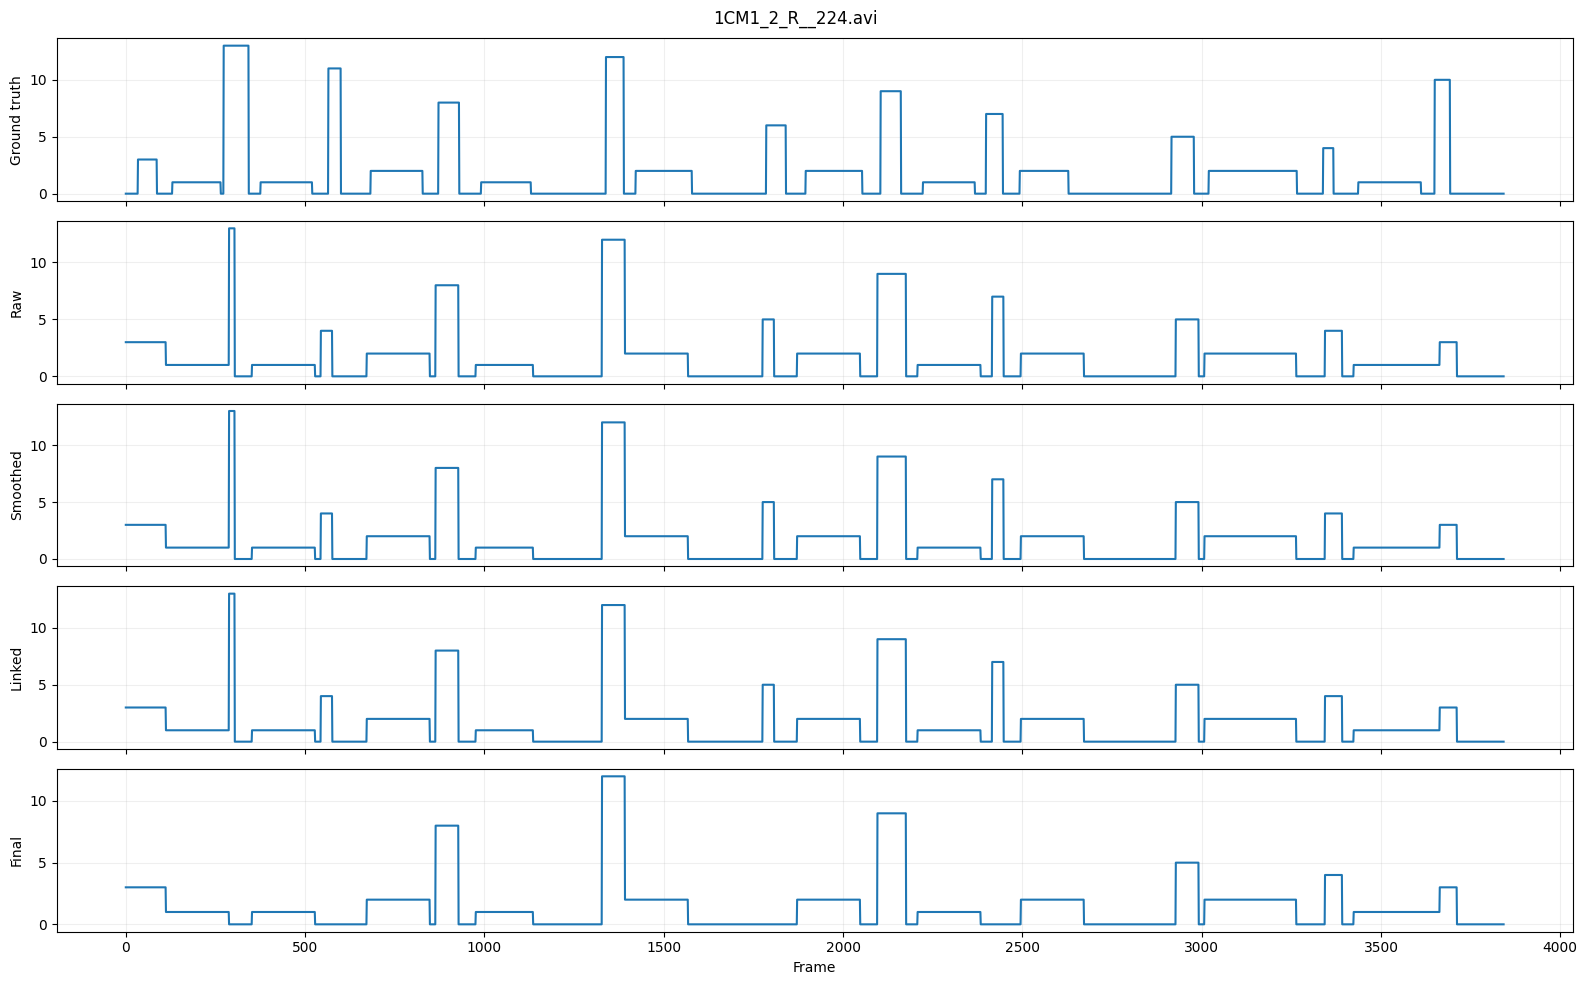

In [9]:
assert CHECKPOINT_LOADED, "IPN-Hand checkpoint is required for continuous evaluation."

video_path = resolve_video_path(CONTINUOUS_VIDEO)
if video_path is None:
    candidate = DATASET_VIDEOS_DIR / CONTINUOUS_VIDEO
    if not candidate.is_file():
        raise FileNotFoundError(CONTINUOUS_VIDEO)
    video_path = candidate

selected_rows = (
    df_test[
        df_test["video"].apply(canonical_video_key)
        == canonical_video_key(Path(video_path).name)
    ]
    .sort_values("t_start")
    .copy()
)

one_video_result = evaluate_continuous_video(
    model,
    Path(video_path),
    selected_rows,
    show_progress=True,
)

print("Video          :", one_video_result["video_path"].name)
print("Frames         :", one_video_result["total_frames"])
print("FPS            :", f"{one_video_result['fps']:.3f}")
print("Duration       :", f"{one_video_result['duration_sec']:.2f} s")
print("Windows        :", one_video_result["num_windows"])
print("Window / step  :", WINDOW_SIZE, "/", WINDOW_STEP)
print("Overlap        :", f"{one_video_result['overlap_ratio']*100:.2f}%")
print("Sample offsets :", one_video_result["sample_offsets"].tolist())
print("Inference      :", f"{one_video_result['infer_elapsed_sec']:.2f} s")
print("Mean / window  :", f"{one_video_result['mean_infer_sec_per_window']*1000:.2f} ms")

display(one_video_result["metrics"])
display(final_segment_table(one_video_result))

if one_video_result["linking_log"]:
    print("Link operations:", len(one_video_result["linking_log"]))
if one_video_result["removal_log"]:
    print("Removal changes:", len(one_video_result["removal_log"]))

plot_continuous_timeline(one_video_result)


### 5.2 Full continuous test split

This loop reuses the exact same `evaluate_continuous_video()` function as the one-video test. No global state is mutated or restored between videos.


In [10]:
ALL_MAX_VIDEOS = None     # set e.g. 5 for a quick test
ALL_SAVE_CSV = True
SAVE_RAW_POSTPROCESS_CACHE = True
POSTPROCESS_CACHE_PATH = "/kaggle/working/videomamba_postprocess_raw_cache.pkl"

valid_test = df_test[df_test["video_found"]].copy()
valid_test["_video_key"] = valid_test["video"].apply(canonical_video_key)

video_groups = []
for video_key, rows in valid_test.groupby("_video_key", sort=True):
    rows = rows.sort_values("t_start").copy()
    path = Path(rows.iloc[0]["video_path"])
    if path.is_file():
        video_groups.append((video_key, path, rows))

if ALL_MAX_VIDEOS is not None:
    video_groups = video_groups[:int(ALL_MAX_VIDEOS)]

records = []

# Raw inference cache: one entry per video. This is reused by Section 5.3,
# so post-processing ablations do NOT rerun VideoMamba forward inference.
continuous_raw_cache = {}

total_raw_correct = 0
total_final_correct = 0
total_frames_weighted = 0

for video_key, path, rows in tqdm(
    video_groups,
    total=len(video_groups),
    desc="Continuous test videos",
):
    result = evaluate_continuous_video(
        model,
        path,
        rows,
        show_progress=False,
    )

    # Keep only the raw model output + metadata required to rerun
    # smoothing/linking/removing and metrics without model inference.
    continuous_raw_cache[path.name] = {
        "video": path.name,
        "fps": float(result["fps"]),
        "total_frames": int(result["total_frames"]),
        "window_starts": np.asarray(result["window_starts"], dtype=np.int64),
        "window_ends": np.asarray(result["window_ends"], dtype=np.int64),
        "P_raw": np.asarray(result["P_raw"], dtype=np.float32),
        "gt_labels": np.asarray(result["gt_labels"], dtype=np.int64),
        "gt_segments": [dict(seg) for seg in result["gt_segments"]],
    }

    metric_map = result["metrics"].set_index("Stage")

    raw_acc = float(metric_map.loc["Raw", "Frame-wise Accuracy"])
    raw_overlap = float(metric_map.loc["Raw", "Temporal Overlap Score"])
    final_acc = float(
        metric_map.loc["After removing (final)", "Frame-wise Accuracy"]
    )
    final_overlap = float(
        metric_map.loc["After removing (final)", "Temporal Overlap Score"]
    )

    total_frames = int(result["total_frames"])
    total_raw_correct += int(np.sum(result["raw_labels"] == result["gt_labels"]))
    total_final_correct += int(np.sum(result["final_labels"] == result["gt_labels"]))
    total_frames_weighted += total_frames

    records.append({
        "video": path.name,
        "frames": total_frames,
        "fps": result["fps"],
        "duration_sec": result["duration_sec"],
        "windows": result["num_windows"],
        "overlap_percent": 100.0 * result["overlap_ratio"],
        "raw_frame_accuracy": raw_acc,
        "raw_temporal_overlap": raw_overlap,
        "final_frame_accuracy": final_acc,
        "final_temporal_overlap": final_overlap,
        "final_gesture_segments": len(result["final_segments"]),
        "link_operations": len(result["linking_log"]),
        "removal_changes": len(result["removal_log"]),
        "inference_sec": result["infer_elapsed_sec"],
        "mean_ms_per_window": 1000.0 * result["mean_infer_sec_per_window"],
    })

continuous_per_video = pd.DataFrame(records)

dataset_summary = pd.DataFrame({
    "Metric": [
        "Videos",
        "Mean per-video raw Frame Accuracy",
        "Mean per-video final Frame Accuracy",
        "Global raw Frame Accuracy",
        "Global final Frame Accuracy",
        "Mean per-video raw Temporal Overlap",
        "Mean per-video final Temporal Overlap",
    ],
    "Value": [
        len(continuous_per_video),
        continuous_per_video["raw_frame_accuracy"].mean(),
        continuous_per_video["final_frame_accuracy"].mean(),
        total_raw_correct / total_frames_weighted,
        total_final_correct / total_frames_weighted,
        continuous_per_video["raw_temporal_overlap"].mean(),
        continuous_per_video["final_temporal_overlap"].mean(),
    ],
})

display(dataset_summary)
display(continuous_per_video.head())

if ALL_SAVE_CSV:
    CONTINUOUS_CSV = "/kaggle/working/videomamba_ipn_continuous_per_video.csv"
    CONTINUOUS_SUMMARY_CSV = "/kaggle/working/videomamba_ipn_continuous_summary.csv"

    continuous_per_video.to_csv(CONTINUOUS_CSV, index=False)
    dataset_summary.to_csv(CONTINUOUS_SUMMARY_CSV, index=False)

    print("Saved:")
    print(" -", CONTINUOUS_CSV)
    print(" -", CONTINUOUS_SUMMARY_CSV)


# ---------------------------------------------------------------------
# Save the raw inference cache so Section 5.3 can be rerun independently
# of VideoMamba inference within the same Kaggle session.
# ---------------------------------------------------------------------
if SAVE_RAW_POSTPROCESS_CACHE:
    import pickle
    with open(POSTPROCESS_CACHE_PATH, "wb") as f:
        pickle.dump(continuous_raw_cache, f, protocol=pickle.HIGHEST_PROTOCOL)

    cache_bytes = Path(POSTPROCESS_CACHE_PATH).stat().st_size
    print(
        f"Raw post-processing cache saved: {POSTPROCESS_CACHE_PATH} "
        f"({cache_bytes / 1024**2:.2f} MiB)"
    )
    print(
        "Post-processing ablations can now be rerun without model inference."
    )


Continuous test videos:   0%|          | 0/52 [00:00<?, ?it/s]

,Metric,Value
0,Videos,52.000000
1,Mean per-video raw Frame Accuracy,0.834889
2,Mean per-video final Frame Accuracy,0.834946
3,Global raw Frame Accuracy,0.837308
4,Global final Frame Accuracy,0.837341
5,Mean per-video raw Temporal Overlap,0.491110
6,Mean per-video final Temporal Overlap,0.494080


,video,frames,fps,duration_sec,windows,overlap_percent,raw_frame_accuracy,raw_temporal_overlap,final_frame_accuracy,final_temporal_overlap,final_gesture_segments,link_operations,removal_changes,inference_sec,mean_ms_per_window
0,1CM1_1_R__217.avi,3987,30.0,132.900000,247,75.0,0.587911,0.045687,0.607976,0.058741,18,1,8,73.044624,295.727224
1,1CM1_1_R__218.avi,3784,30.0,126.133333,234,75.0,0.512949,0.000000,0.542548,0.023124,16,2,6,67.633317,289.031269
2,1CM1_1_R__219.avi,3921,30.0,130.700000,243,75.0,0.630196,0.114892,0.646519,0.211224,23,4,4,69.104881,284.382225
3,1CM1_1_R__220.avi,3889,30.0,129.633333,241,75.0,0.743379,0.201448,0.749036,0.212852,21,1,5,68.571711,284.529920
4,1CM1_2_R__221.avi,3796,30.0,126.533333,235,75.0,0.804268,0.497396,0.784510,0.432182,15,0,6,68.721772,292.433074


Saved:
 - /kaggle/working/videomamba_ipn_continuous_per_video.csv
 - /kaggle/working/videomamba_ipn_continuous_summary.csv
Raw post-processing cache saved: /kaggle/working/videomamba_postprocess_raw_cache.pkl (2.55 MiB)
Post-processing ablations can now be rerun without model inference.


### 5.4 P1: Segment-level CVPR metrics and error/control example manifests

RAW window prediction only. Reports F1@10/25/50 temporal IoU, Edit, IPN diagnostic Levenshtein, ECE/Brier/NLL, plus correctly and incorrectly recognized segments. Manifests are for later visualization. No external GPU pass.


In [ ]:
# P1 offline RAW continuous evaluation + manifest of wrong AND correct examples.
# Segmental F1@{10,25,50} and Edit follow CVPR MS-TCN conventions.
# These scores are NOT RSC's causal Online-F1/Early@10/TTC.
from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support

P1_IPN_DIR = Path("/kaggle/working/p1_ipn_re_evaluation")
P1_IPN_DIR.mkdir(parents=True, exist_ok=True)

def p1_segments(labels, ignore_background=True):
    labels = np.asarray(labels, dtype=np.int64)
    if not len(labels):
        return []
    boundaries = np.r_[0, np.flatnonzero(labels[1:] != labels[:-1])+1, len(labels)]
    return [(int(labels[a]), int(a), int(b-1)) for a, b in zip(boundaries[:-1], boundaries[1:])
            if not (ignore_background and int(labels[a]) == 0)]

def p1_edit_distance(a, b):
    prev = list(range(len(b)+1))
    for i, x in enumerate(a, 1):
        curr = [i]+[0]*len(b)
        for j, y in enumerate(b, 1):
            curr[j] = min(curr[j-1]+1, prev[j]+1, prev[j-1]+(x!=y))
        prev = curr
    return int(prev[-1])

def p1_segment_counts(gt_segs, pred_segs, threshold):
    # One-to-one class-consistent temporal IoU matching.
    matched = set()
    tp, fp = 0, 0
    for p_label, p_start, p_end in pred_segs:
        best_i, best_iou = None, -1.0
        for i, (g_label, g_start, g_end) in enumerate(gt_segs):
            if i in matched or p_label != g_label:
                continue
            intersection = max(0, min(p_end, g_end)-max(p_start, g_start)+1)
            union = (p_end-p_start+1)+(g_end-g_start+1)-intersection
            iou = intersection / union if union else 0.0
            if iou > best_iou:
                best_i, best_iou = i, iou
        if best_i is not None and best_iou >= threshold:
            matched.add(best_i)
            tp += 1
        else:
            fp += 1
    return tp, fp, len(gt_segs)-tp

def p1_ece(probs, y, bins=15):
    conf = np.max(probs, axis=1)
    correct = (np.argmax(probs, axis=1) == y).astype(float)
    edges = np.linspace(0.0, 1.0, bins+1)
    ece = 0.0
    for k in range(bins):
        in_bin = (conf >= edges[k]) & ((conf < edges[k+1]) if k < bins-1 else (conf <= edges[k+1]))
        if np.any(in_bin):
            ece += np.mean(in_bin)*abs(np.mean(correct[in_bin])-np.mean(conf[in_bin]))
    return float(ece)

# Isolated calibration, with unchanged raw softmax (no test-set tuning).
iso = isolated_results.copy()
prob_cols = [f"prob_{i}" for i in range(NUM_CLASSES)]
assert set(prob_cols).issubset(iso.columns), "Run updated isolated Section 4 first."
probs = iso[prob_cols].to_numpy(dtype=float)
y_iso = iso["gt_idx"].to_numpy(dtype=int)
assert np.allclose(probs.sum(axis=1), 1., atol=1e-4)
brier = float(np.mean(np.sum((probs-np.eye(NUM_CLASSES)[y_iso])**2, axis=1)))
calibration = {"n": int(len(y_iso)), "ece_15": p1_ece(probs, y_iso),
               "multiclass_brier_sum": brier, "nll": float(
                   -np.log(np.clip(probs[np.arange(len(y_iso)), y_iso], 1e-12, 1)).mean())}
(P1_IPN_DIR/"isolated_calibration.json").write_text(json.dumps(calibration, indent=2))
iso_wrong = iso[iso.gt_idx != iso.pred_idx].copy().sort_values("confidence", ascending=False)
iso_right = iso[iso.gt_idx == iso.pred_idx].copy().sort_values("confidence", ascending=False)
iso_wrong.to_csv(P1_IPN_DIR/"isolated_error_cases.csv", index=False)
iso_right.to_csv(P1_IPN_DIR/"isolated_correct_cases.csv", index=False)

assert continuous_raw_cache, "Run full continuous Section 5.2 first."
per_video = []
all_gt, all_pred = [], []
counts = {t: np.zeros(3, dtype=int) for t in (0.10, 0.25, 0.50)}
errors, controls = [], []
for name, entry in sorted(continuous_raw_cache.items()):
    gt = np.asarray(entry["gt_labels"], dtype=np.int64)
    p_frame = windows_to_frame_probs(
        np.asarray(entry["P_raw"]), np.asarray(entry["window_starts"]),
        np.asarray(entry["window_ends"]), len(gt))
    pred = p_frame.argmax(axis=1).astype(np.int64)
    assert len(gt) == len(pred) and len(gt)>0
    gs, ps = p1_segments(gt), p1_segments(pred)
    row = {"video": name, "frames": len(gt),
           "frame_accuracy": float(accuracy_score(gt, pred)),
           "macro_f1": float(f1_score(gt, pred, labels=list(range(NUM_CLASSES)),
                                        average="macro", zero_division=0))}
    for t in counts:
        a = np.array(p1_segment_counts(gs, ps, t), dtype=int)
        counts[t] += a
        row[f"segment_f1_at_{int(t*100)}"] = (2*a[0]/(2*a[0]+a[1]+a[2])) if (2*a[0]+a[1]+a[2]) else 0.
    dist = p1_edit_distance([s[0] for s in gs], [s[0] for s in ps])
    row["edit_distance"] = dist
    row["edit_score_ms_tcn_pct"] = 100*(1-dist/max(len(gs), len(ps), 1))
    row["ipn_gt_normalized_levenshtein_pct"] = 100*(1-dist/max(len(gs),1))
    per_video.append(row)
    all_gt.append(gt); all_pred.append(pred)
    for correct, sink in ((False, errors), (True, controls)):
        match = (gt == pred) if correct else (gt != pred)
        # For controls require a gesture; avoid selecting easy background-only frames.
        if correct:
            match &= (gt != 0)
        for _, a, b in p1_segments(match.astype(np.int64), ignore_background=True):
            mid = (a+b)//2
            sink.append({"video": name, "video_path": str(resolve_video_path(name)),
                         "start": a+1, "end": b+1, "indexing": "IPN_1_based",
                         "gt_idx": int(gt[mid]), "pred_idx": int(pred[mid]),
                         "duration_frames": b-a+1, "correct": bool(correct)})
per = pd.DataFrame(per_video)
per.to_csv(P1_IPN_DIR/"continuous_raw_segment_metrics_per_video.csv", index=False)
for filename, cases in (("continuous_error_cases.csv", errors), ("continuous_correct_cases.csv", controls)):
    df = pd.DataFrame(cases).sort_values("duration_frames", ascending=False) if cases else pd.DataFrame()
    df.to_csv(P1_IPN_DIR/filename, index=False)
gt_all = np.concatenate(all_gt); pr_all = np.concatenate(all_pred)
summary = {"videos": len(per), "frames": len(gt_all),
           "global_frame_accuracy": float(accuracy_score(gt_all, pr_all)),
           "global_macro_f1": float(f1_score(gt_all, pr_all, labels=list(range(NUM_CLASSES)),
                                              average="macro", zero_division=0)),
           "edit_score_ms_tcn_mean_pct": float(per.edit_score_ms_tcn_pct.mean()),
           "ipn_levenshtein_gt_normalized_mean_pct_diagnostic": float(per.ipn_gt_normalized_levenshtein_pct.mean()),
           "protocol": "raw offline overlapping windows; IPN gesture labels exclude class 0 in segment metrics"}
for t, (tp, fp, fn) in counts.items():
    summary[f"segment_f1_at_{int(t*100)}"] = float(2*tp/(2*tp+fp+fn)) if (2*tp+fp+fn) else 0.
(P1_IPN_DIR/"continuous_raw_segment_metrics_summary.json").write_text(json.dumps(summary, indent=2))
print("Isolated calibration:", calibration)
print("Continuous RAW summary:", summary)
print("Visualization case CSVs exported; no image style is imposed.")


### P1 Continuous — keyframes with temporal context (correct vs error)

For each complete GT gesture segment, compare predicted class and temporal IoU. Display five representative video frames plus time-aligned GT/RAW Prediction stripes. False positives are also eligible. The visualization is *offline*, not causal. Output PNG + candidate CSV.


In [ ]:
# P1 continuous qualitative evaluation: temporal segments, not isolated clips.
# Error examples: missed gesture / class confusion / boundary mismatch / false positive.
# Correct controls: GT gesture segment with class-matched predicted segment tIoU >= 0.50.
# Each case has 5 original frames and a CONTEXTUAL GT-vs-RAW-Pred timeline.
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

P1_CONT_DIR = P1_IPN_DIR / "continuous_timeline_keyframes"
P1_CONT_DIR.mkdir(parents=True, exist_ok=True)
P1_CONT_MAX_ERRORS = 8
P1_CONT_MAX_CORRECT = 8
P1_CONT_CONTEXT_SEC = 1.5

def p1_cont_iou(a, b):
    # Each segment = (label, start, end), inclusive, 0-based.
    inter = max(0, min(a[2],b[2]) - max(a[1],b[1]) + 1)
    union = (a[2]-a[1]+1) + (b[2]-b[1]+1) - inter
    return inter / union if union else 0.

def p1_cont_render(case, gt, pred, fps, path, dest):
    start, end = int(case["start"]), int(case["end"])
    n = len(gt)
    if not Path(path).is_file():
        raise FileNotFoundError(path)
    selected = np.rint(np.linspace(start, end, 5)).astype(int)
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video {path}")
    frames = []
    try:
        for idx in selected:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ok, bgr = cap.read()
            if not ok:
                raise RuntimeError(f"Cannot read frame {idx} of {path}")
            frames.append(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    finally:
        cap.release()

    fig = plt.figure(figsize=(16, 5.4), constrained_layout=True)
    grid = fig.add_gridspec(2, 5, height_ratios=[2.3, 1.0])
    for j, (img, idx) in enumerate(zip(frames, selected)):
        ax = fig.add_subplot(grid[0, j])
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"frame {idx} | {idx/fps:.2f}s", fontsize=10)
    ax = fig.add_subplot(grid[1, :])
    context = max(10, int(np.ceil(P1_CONT_CONTEXT_SEC * fps)))
    left = max(0, start-context)
    right = min(n-1, end+context)
    cmap = ListedColormap(plt.get_cmap("tab20", NUM_CLASSES)(
        np.arange(NUM_CLASSES)))
    ax.imshow(np.vstack([gt[left:right+1], pred[left:right+1]]),
              interpolation="nearest", aspect="auto", cmap=cmap,
              vmin=-0.5, vmax=NUM_CLASSES-0.5,
              extent=(left-0.5,right+0.5,1.5,-0.5))
    ax.axvspan(start-0.5, end+0.5,
               color=("red" if case["type"]=="error" else "green"),
               alpha=0.15)
    ax.axvline(start-0.5, color="black", linewidth=0.8, linestyle="--")
    ax.axvline(end+0.5, color="black", linewidth=0.8, linestyle="--")
    ax.set_yticks([0,1],["Ground Truth","RAW Prediction"])
    ax.set_xlim(left-0.5,right+0.5)
    ax.set_xlabel("Frame index (0-based); prediction is OFFLINE, may use future frames")
    ax.grid(axis="x", alpha=0.2)
    fig.suptitle(
        f"CONTINUOUS {case['type'].upper()} | video {case['video']} | "
        f"{case['reason']} | GT={CLASS_CODES[int(case['gt_class'])]} "
        f"Pred(mid)={CLASS_CODES[int(case['pred_class'])]} | "
        f"segment={start}..{end}, tIoU={case['best_iou']:.2f}", fontsize=11)
    fig.savefig(dest, dpi=170, bbox_inches="tight")
    plt.close(fig)

p1_video_arrays = {}
p1_cases = []
for video, entry in sorted(continuous_raw_cache.items()):
    gt = np.asarray(entry["gt_labels"], dtype=np.int64)
    raw = windows_to_frame_probs(
        np.asarray(entry["P_raw"]), np.asarray(entry["window_starts"]),
        np.asarray(entry["window_ends"]), len(gt))
    pred = raw.argmax(axis=1).astype(np.int64)
    fps = max(1., float(entry["fps"]))
    path = str(resolve_video_path(str(video)))
    p1_video_arrays[str(video)] = (gt,pred,fps,path)
    g_segments = p1_segments(gt)
    p_segments = p1_segments(pred)
    # Evaluate complete annotated gesture intervals, not merely consecutive correct frames.
    for g in g_segments:
        same = [p for p in p_segments if p[0]==g[0]]
        best = max([p1_cont_iou(g,p) for p in same], default=0.)
        start,end = g[1],g[2]
        mid = (start+end)//2
        pmid = int(pred[mid])
        if best >= 0.50:
            typ, reason = "correct", "correct_class_tIoU_ge_0.50"
        elif best > 0.:
            typ, reason = "error", "boundary_or_fragmentation"
        elif np.any(pred[start:end+1] != 0):
            typ, reason = "error", "class_confusion"
        else:
            typ, reason = "error", "missed_gesture"
        p1_cases.append({
            "video":str(video),"type":typ,"reason":reason,
            "start":int(start),"end":int(end),"duration_frames":int(end-start+1),
            "gt_class":int(g[0]),"pred_class":pmid,"best_iou":float(best),
            "fps":fps,"video_path":str(path)})
    # Explicit false-positive proposals: most GT frames are background.
    for p in p_segments:
        same = [g for g in g_segments if g[0]==p[0]]
        best = max([p1_cont_iou(p,g) for g in same],default=0.)
        st,en=p[1],p[2]
        if best < 0.10 and np.mean(gt[st:en+1]==0)>0.5:
            mid=(st+en)//2
            p1_cases.append({
                "video":str(video),"type":"error","reason":"false_positive_on_background",
                "start":int(st),"end":int(en),"duration_frames":int(en-st+1),
                "gt_class":int(gt[mid]),"pred_class":int(pred[mid]),
                "best_iou":float(best),"fps":fps,"video_path":str(path)})

case_df = pd.DataFrame(p1_cases)
case_df.to_csv(P1_CONT_DIR / "continuous_segment_candidates.csv", index=False)
if not case_df.empty:
    errors=case_df[case_df.type=="error"].sort_values("duration_frames",ascending=False)
    good=case_df[case_df.type=="correct"].sort_values("duration_frames",ascending=False)
    # Select diverse error types before filling remaining slots by duration.
    error_list=[];seen=set()
    for _, candidate in errors.iterrows():
        if candidate["reason"] not in seen:
            error_list.append(candidate); seen.add(candidate["reason"])
    selected_starts={(str(x["video"]),int(x["start"]),int(x["end"])) for x in error_list}
    for _, candidate in errors.iterrows():
        key=(str(candidate["video"]),int(candidate["start"]),int(candidate["end"]))
        if len(error_list)>=P1_CONT_MAX_ERRORS: break
        if key not in selected_starts:
            error_list.append(candidate); selected_starts.add(key)
    error_list=error_list[:P1_CONT_MAX_ERRORS]
    for typ, group in (("error",error_list),
                       ("correct",[row for _,row in good.head(P1_CONT_MAX_CORRECT).iterrows()])):
        for rank, case in enumerate(group,1):
            gt,pred,fps,path=p1_video_arrays[str(case["video"])]
            outfile=P1_CONT_DIR/f"continuous_{typ}_{rank:03d}.png"
            p1_cont_render(case,gt,pred,fps,path,outfile)
    print(f"Continuous: {len(errors)} error candidates, {len(good)} correct "
          f"gesture segments; rendered {len(error_list)} errors and "
          f"{min(len(good),P1_CONT_MAX_CORRECT)} correct controls in {P1_CONT_DIR}")
else:
    print("No continuous gesture segments to visualize.")


### 5.3 Post-processing ablation — one inference pass, many configurations

This section **does not run VideoMamba inference again**. It reuses the raw
per-window probabilities cached by Section 5.2 and evaluates the requested
post-processing sequence:

| Test | Smoothing | T_AVG (s) | MIN_GESTURE (s) | Fill |
|---|---|---:|---:|---|
| Raw | Off | 0 | 0 | False |
| L1 | Off | 0.3 | 0 | False |
| L2 | Off | 0.7 | 0 | False |
| L3 | Off | 1.0 | 0 | False |
| R1 | Off | best T_AVG | 0.5 | False |
| R2 | Off | best T_AVG | 0.7 | False |
| R3 | Off | best T_AVG | 1.0 | False |
| R4 | Off | best T_AVG | 1.5 | False |
| F1 | Off | best T_AVG | best MIN_GESTURE | True |
| S1 | On | best T_AVG | best MIN_GESTURE | False |
| S2 | On | best T_AVG | best MIN_GESTURE | True |

The default selection criterion is **mean per-video Frame Accuracy**, with
**mean Temporal Overlap** as the tie-breaker. Gesture Recall is also reported
so a configuration that improves background-heavy frame accuracy by deleting
real gestures can be detected.

`THETA_SEC` is used only for evaluation/matching; it does not alter predictions.


In [11]:
# =============================================================================
# 5.3 POST-PROCESSING ABLATION
# One VideoMamba inference pass -> many post-processing configurations
# =============================================================================
import pickle
import time
from pathlib import Path

POSTPROCESS_CACHE_PATH = globals().get(
    "POSTPROCESS_CACHE_PATH",
    "/kaggle/working/videomamba_postprocess_raw_cache.pkl",
)

# -------------------------------------------------------------------------
# Load cache from RAM if Section 5.2 was just executed. Otherwise load disk.
# -------------------------------------------------------------------------
if "continuous_raw_cache" not in globals() or not continuous_raw_cache:
    cache_path = Path(POSTPROCESS_CACHE_PATH)
    if not cache_path.is_file():
        raise FileNotFoundError(
            "Raw inference cache not found. Run Section 5.2 once first. "
            f"Expected: {cache_path}"
        )
    with cache_path.open("rb") as f:
        continuous_raw_cache = pickle.load(f)
    print(f"Loaded raw inference cache: {cache_path}")
else:
    print("Using raw inference cache already present in RAM.")

print("Cached videos:", len(continuous_raw_cache))

# -------------------------------------------------------------------------
# Selection policy
# -------------------------------------------------------------------------
# Main goal requested here: improve continuous Frame Accuracy.
# Temporal Overlap is used as a tie-breaker.
PRIMARY_SELECTION_METRIC = "mean_frame_accuracy"
TIE_BREAK_METRIC = "mean_temporal_overlap"

# If every nonzero linking threshold is worse than Raw, allow T_AVG=0 to win.
ALLOW_RAW_AS_BEST_LINK = True

# Requested sweep values.
LINK_THRESHOLDS_SEC = [0.3, 0.7, 1.0]
MIN_GESTURE_THRESHOLDS_SEC = [0.5, 0.7, 1.0, 1.5]

# Evaluation tolerance only.
ABLATION_THETA_SEC = float(THETA_SEC)

def gesture_recall_with_tolerance(gt, pred, theta_frames):
    """
    Greedy one-to-one same-class matching under the same start/end tolerance
    used by overlap_score(). Returns fraction of GT gesture segments matched.
    """
    gt = sorted(gt, key=lambda x: x["start"])
    pred = sorted(pred, key=lambda x: x["start"])

    if len(gt) == 0:
        return 1.0

    used = set()
    matched = 0

    for g in gt:
        candidates = []
        for j, p in enumerate(pred):
            if j in used or int(p["label"]) != int(g["label"]):
                continue
            if abs(int(p["start"]) - int(g["start"])) > theta_frames:
                continue
            if abs(int(p["end"]) - int(g["end"])) > theta_frames:
                continue
            candidates.append((temporal_iou(p, g), j))

        if candidates:
            _, best_j = max(candidates, key=lambda x: x[0])
            used.add(best_j)
            matched += 1

    return matched / len(gt)

def apply_postprocess_to_cached_video(
    cache_entry,
    *,
    enable_smoothing,
    t_avg_sec,
    min_gesture_sec,
    fill_same_neighbors,
    theta_sec,
):
    fps = float(cache_entry["fps"])
    total_frames = int(cache_entry["total_frames"])
    starts = np.asarray(cache_entry["window_starts"], dtype=np.int64)
    ends = np.asarray(cache_entry["window_ends"], dtype=np.int64)
    p_raw = np.asarray(cache_entry["P_raw"], dtype=np.float32)
    gt_labels = np.asarray(cache_entry["gt_labels"], dtype=np.int64)
    gt_segments = [dict(seg) for seg in cache_entry["gt_segments"]]

    # No model forward here.
    p_stage = smooth_window_probs(
        p_raw,
        enabled=bool(enable_smoothing),
    )
    p_frame = windows_to_frame_probs(
        p_stage,
        starts,
        ends,
        total_frames,
    )
    stage_labels = np.argmax(p_frame, axis=1).astype(np.int64)

    max_gap_frames = int(round(float(t_avg_sec) * fps))
    min_frames = int(round(float(min_gesture_sec) * fps))
    theta_frames = int(round(float(theta_sec) * fps))

    linked_labels, linking_log = link_same_label_across_gaps(
        stage_labels,
        max_gap_frames,
        fps,
    )

    final_labels, removal_log = remove_short_gesture_segments(
        linked_labels,
        min_frames,
        fps,
        fill_same_neighbors=bool(fill_same_neighbors),
    )

    pred_segments = gesture_segments(final_labels)

    return {
        "frame_accuracy": float(np.mean(final_labels == gt_labels)),
        "temporal_overlap": overlap_score(
            gt_segments,
            pred_segments,
            theta_frames,
        ),
        "gesture_recall": gesture_recall_with_tolerance(
            gt_segments,
            pred_segments,
            theta_frames,
        ),
        "pred_segments": int(len(pred_segments)),
        "gt_segments": int(len(gt_segments)),
        "link_operations": int(len(linking_log)),
        "removal_changes": int(len(removal_log)),
        "correct_frames": int(np.sum(final_labels == gt_labels)),
        "total_frames": total_frames,
    }

def evaluate_postprocess_config(config):
    t0 = time.perf_counter()
    per_video_rows = []

    total_correct = 0
    total_frames = 0
    total_pred_segments = 0
    total_gt_segments = 0
    total_links = 0
    total_removals = 0

    for video_name, cache_entry in continuous_raw_cache.items():
        metrics = apply_postprocess_to_cached_video(
            cache_entry,
            enable_smoothing=config["smoothing"],
            t_avg_sec=config["t_avg_sec"],
            min_gesture_sec=config["min_gesture_sec"],
            fill_same_neighbors=config["fill"],
            theta_sec=ABLATION_THETA_SEC,
        )

        per_video_rows.append({
            "test": config["test"],
            "video": video_name,
            **metrics,
        })

        total_correct += metrics["correct_frames"]
        total_frames += metrics["total_frames"]
        total_pred_segments += metrics["pred_segments"]
        total_gt_segments += metrics["gt_segments"]
        total_links += metrics["link_operations"]
        total_removals += metrics["removal_changes"]

    per_video_df = pd.DataFrame(per_video_rows)
    elapsed = time.perf_counter() - t0

    summary = {
        "test": config["test"],
        "smoothing": bool(config["smoothing"]),
        "t_avg_sec": float(config["t_avg_sec"]),
        "min_gesture_sec": float(config["min_gesture_sec"]),
        "fill": bool(config["fill"]),
        "videos": int(len(per_video_df)),
        "mean_frame_accuracy": float(per_video_df["frame_accuracy"].mean()),
        "global_frame_accuracy": (
            float(total_correct / total_frames) if total_frames else np.nan
        ),
        "mean_temporal_overlap": float(
            per_video_df["temporal_overlap"].mean()
        ),
        "mean_gesture_recall": float(
            per_video_df["gesture_recall"].mean()
        ),
        "total_gt_segments": int(total_gt_segments),
        "total_pred_segments": int(total_pred_segments),
        "total_link_operations": int(total_links),
        "total_removal_changes": int(total_removals),
        "postprocess_sec": float(elapsed),
    }
    return summary, per_video_df

def choose_best(summary_df, candidate_tests):
    candidates = summary_df[
        summary_df["test"].isin(candidate_tests)
    ].copy()

    if candidates.empty:
        raise ValueError(f"No candidates found: {candidate_tests}")

    candidates = candidates.sort_values(
        [PRIMARY_SELECTION_METRIC, TIE_BREAK_METRIC],
        ascending=[False, False],
    )
    return candidates.iloc[0]

all_summaries = []
all_per_video = []

# -------------------------------------------------------------------------
# Stage A: Raw + linking threshold sweep
# -------------------------------------------------------------------------
stage_a_configs = [
    {
        "test": "Raw",
        "smoothing": False,
        "t_avg_sec": 0.0,
        "min_gesture_sec": 0.0,
        "fill": False,
    },
    {
        "test": "L1",
        "smoothing": False,
        "t_avg_sec": 0.3,
        "min_gesture_sec": 0.0,
        "fill": False,
    },
    {
        "test": "L2",
        "smoothing": False,
        "t_avg_sec": 0.7,
        "min_gesture_sec": 0.0,
        "fill": False,
    },
    {
        "test": "L3",
        "smoothing": False,
        "t_avg_sec": 1.0,
        "min_gesture_sec": 0.0,
        "fill": False,
    },
]

print("\n=== Stage A: T_AVG sweep ===")
for cfg in stage_a_configs:
    summary, per_video = evaluate_postprocess_config(cfg)
    all_summaries.append(summary)
    all_per_video.append(per_video)
    print(
        f'{cfg["test"]:>3s} | T_AVG={cfg["t_avg_sec"]:.1f}s | '
        f'FrameAcc={summary["mean_frame_accuracy"]:.6f} | '
        f'Overlap={summary["mean_temporal_overlap"]:.6f} | '
        f'Recall={summary["mean_gesture_recall"]:.6f}'
    )

summary_df = pd.DataFrame(all_summaries)

link_candidates = ["L1", "L2", "L3"]
if ALLOW_RAW_AS_BEST_LINK:
    link_candidates = ["Raw"] + link_candidates

best_link = choose_best(summary_df, link_candidates)
BEST_T_AVG_SEC = float(best_link["t_avg_sec"])

print(
    f"\nBest linking config: {best_link['test']} -> "
    f"T_AVG={BEST_T_AVG_SEC:.1f}s "
    f"(selected by {PRIMARY_SELECTION_METRIC})"
)

# -------------------------------------------------------------------------
# Stage B: MIN_GESTURE sweep using best T_AVG
# -------------------------------------------------------------------------
stage_b_configs = [
    {
        "test": f"R{i+1}",
        "smoothing": False,
        "t_avg_sec": BEST_T_AVG_SEC,
        "min_gesture_sec": threshold,
        "fill": False,
    }
    for i, threshold in enumerate(MIN_GESTURE_THRESHOLDS_SEC)
]

print("\n=== Stage B: MIN_GESTURE sweep ===")
for cfg in stage_b_configs:
    summary, per_video = evaluate_postprocess_config(cfg)
    all_summaries.append(summary)
    all_per_video.append(per_video)
    print(
        f'{cfg["test"]:>3s} | MIN={cfg["min_gesture_sec"]:.1f}s | '
        f'FrameAcc={summary["mean_frame_accuracy"]:.6f} | '
        f'Overlap={summary["mean_temporal_overlap"]:.6f} | '
        f'Recall={summary["mean_gesture_recall"]:.6f}'
    )

summary_df = pd.DataFrame(all_summaries)

# Include best-link/no-removal baseline so removal is not forced to win.
removal_candidates = [str(best_link["test"])] + [
    cfg["test"] for cfg in stage_b_configs
]
best_removal = choose_best(summary_df, removal_candidates)
BEST_MIN_GESTURE_SEC = float(best_removal["min_gesture_sec"])

print(
    f"\nBest removal config: {best_removal['test']} -> "
    f"MIN_GESTURE={BEST_MIN_GESTURE_SEC:.1f}s "
    f"(selected by {PRIMARY_SELECTION_METRIC})"
)

# -------------------------------------------------------------------------
# Stage C: Fill between same-label neighbors
# -------------------------------------------------------------------------
f1_cfg = {
    "test": "F1",
    "smoothing": False,
    "t_avg_sec": BEST_T_AVG_SEC,
    "min_gesture_sec": BEST_MIN_GESTURE_SEC,
    "fill": True,
}

print("\n=== Stage C: Fill same neighbors ===")
summary, per_video = evaluate_postprocess_config(f1_cfg)
all_summaries.append(summary)
all_per_video.append(per_video)

print(
    f' F1 | Fill=True | '
    f'FrameAcc={summary["mean_frame_accuracy"]:.6f} | '
    f'Overlap={summary["mean_temporal_overlap"]:.6f} | '
    f'Recall={summary["mean_gesture_recall"]:.6f}'
)

# -------------------------------------------------------------------------
# Stage D: Smoothing OFF/ON comparison with both fill settings
# -------------------------------------------------------------------------
stage_d_configs = [
    {
        "test": "S1",
        "smoothing": True,
        "t_avg_sec": BEST_T_AVG_SEC,
        "min_gesture_sec": BEST_MIN_GESTURE_SEC,
        "fill": False,
    },
    {
        "test": "S2",
        "smoothing": True,
        "t_avg_sec": BEST_T_AVG_SEC,
        "min_gesture_sec": BEST_MIN_GESTURE_SEC,
        "fill": True,
    },
]

print("\n=== Stage D: Smoothing ===")
for cfg in stage_d_configs:
    summary, per_video = evaluate_postprocess_config(cfg)
    all_summaries.append(summary)
    all_per_video.append(per_video)
    print(
        f'{cfg["test"]:>3s} | Smooth=True | Fill={cfg["fill"]} | '
        f'FrameAcc={summary["mean_frame_accuracy"]:.6f} | '
        f'Overlap={summary["mean_temporal_overlap"]:.6f} | '
        f'Recall={summary["mean_gesture_recall"]:.6f}'
    )

# -------------------------------------------------------------------------
# Final comparison
# -------------------------------------------------------------------------
postprocess_ablation_summary = pd.DataFrame(all_summaries)
postprocess_ablation_per_video = pd.concat(
    all_per_video,
    ignore_index=True,
)

raw_row = postprocess_ablation_summary[
    postprocess_ablation_summary["test"] == "Raw"
].iloc[0]

postprocess_ablation_summary["delta_mean_frame_acc_vs_raw"] = (
    postprocess_ablation_summary["mean_frame_accuracy"]
    - float(raw_row["mean_frame_accuracy"])
)
postprocess_ablation_summary["delta_overlap_vs_raw"] = (
    postprocess_ablation_summary["mean_temporal_overlap"]
    - float(raw_row["mean_temporal_overlap"])
)
postprocess_ablation_summary["delta_recall_vs_raw"] = (
    postprocess_ablation_summary["mean_gesture_recall"]
    - float(raw_row["mean_gesture_recall"])
)

display_cols = [
    "test",
    "smoothing",
    "t_avg_sec",
    "min_gesture_sec",
    "fill",
    "mean_frame_accuracy",
    "global_frame_accuracy",
    "mean_temporal_overlap",
    "mean_gesture_recall",
    "delta_mean_frame_acc_vs_raw",
    "delta_overlap_vs_raw",
    "delta_recall_vs_raw",
    "total_pred_segments",
    "total_link_operations",
    "total_removal_changes",
    "postprocess_sec",
]

print("\n=== Complete post-processing ablation ===")
display(
    postprocess_ablation_summary[display_cols]
    .sort_values(
        [PRIMARY_SELECTION_METRIC, TIE_BREAK_METRIC],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

best_overall = choose_best(
    postprocess_ablation_summary,
    postprocess_ablation_summary["test"].tolist(),
)

print("\n=== Best overall configuration ===")
print("Test               :", best_overall["test"])
print("Smoothing          :", bool(best_overall["smoothing"]))
print("T_AVG_SEC          :", float(best_overall["t_avg_sec"]))
print("MIN_GESTURE_SEC    :", float(best_overall["min_gesture_sec"]))
print("FILL_SAME_NEIGHBORS:", bool(best_overall["fill"]))
print("Mean Frame Accuracy:", f'{best_overall["mean_frame_accuracy"]:.6f}')
print("Global Frame Acc.  :", f'{best_overall["global_frame_accuracy"]:.6f}')
print("Temporal Overlap   :", f'{best_overall["mean_temporal_overlap"]:.6f}')
print("Gesture Recall     :", f'{best_overall["mean_gesture_recall"]:.6f}')
print(
    "NOTE: Selection uses",
    PRIMARY_SELECTION_METRIC,
    "with",
    TIE_BREAK_METRIC,
    "as tie-breaker.",
)

# -------------------------------------------------------------------------
# Export
# -------------------------------------------------------------------------
ABLATION_SUMMARY_CSV = (
    "/kaggle/working/videomamba_postprocess_ablation_summary.csv"
)
ABLATION_PER_VIDEO_CSV = (
    "/kaggle/working/videomamba_postprocess_ablation_per_video.csv"
)

postprocess_ablation_summary.to_csv(
    ABLATION_SUMMARY_CSV,
    index=False,
)
postprocess_ablation_per_video.to_csv(
    ABLATION_PER_VIDEO_CSV,
    index=False,
)

print("\nSaved:")
print(" -", ABLATION_SUMMARY_CSV)
print(" -", ABLATION_PER_VIDEO_CSV)


Using raw inference cache already present in RAM.
Cached videos: 52

=== Stage A: T_AVG sweep ===
Raw | T_AVG=0.0s | FrameAcc=0.834889 | Overlap=0.491110 | Recall=0.788995
 L1 | T_AVG=0.3s | FrameAcc=0.834889 | Overlap=0.491110 | Recall=0.788995
 L2 | T_AVG=0.7s | FrameAcc=0.835040 | Overlap=0.492561 | Recall=0.787206
 L3 | T_AVG=1.0s | FrameAcc=0.835040 | Overlap=0.492561 | Recall=0.787206

Best linking config: L2 -> T_AVG=0.7s (selected by mean_frame_accuracy)

=== Stage B: MIN_GESTURE sweep ===
 R1 | MIN=0.5s | FrameAcc=0.835040 | Overlap=0.492561 | Recall=0.787206
 R2 | MIN=0.7s | FrameAcc=0.835149 | Overlap=0.507743 | Recall=0.763760
 R3 | MIN=1.0s | FrameAcc=0.835249 | Overlap=0.507705 | Recall=0.762844
 R4 | MIN=1.5s | FrameAcc=0.833291 | Overlap=0.511539 | Recall=0.724757

Best removal config: R3 -> MIN_GESTURE=1.0s (selected by mean_frame_accuracy)

=== Stage C: Fill same neighbors ===
 F1 | Fill=True | FrameAcc=0.835249 | Overlap=0.507705 | Recall=0.762844

=== Stage D: Smoot

,test,smoothing,t_avg_sec,min_gesture_sec,fill,mean_frame_accuracy,global_frame_accuracy,mean_temporal_overlap,mean_gesture_recall,delta_mean_frame_acc_vs_raw,delta_overlap_vs_raw,delta_recall_vs_raw,total_pred_segments,total_link_operations,total_removal_changes,postprocess_sec
0,R3,False,0.7,1.0,False,0.835249,0.837671,0.507705,0.762844,0.000361,0.016595,-0.026151,1136,8,94,0.229243
1,F1,False,0.7,1.0,True,0.835249,0.837671,0.507705,0.762844,0.000361,0.016595,-0.026151,1136,8,94,0.231709
2,R2,False,0.7,0.7,False,0.835149,0.837572,0.507743,0.763760,0.000261,0.016633,-0.025236,1137,8,93,0.245962
3,L2,False,0.7,0.0,False,0.835040,0.837478,0.492561,0.787206,0.000151,0.001450,-0.001790,1230,8,0,0.232009
4,L3,False,1.0,0.0,False,0.835040,0.837478,0.492561,0.787206,0.000151,0.001450,-0.001790,1230,8,0,0.240476
5,R1,False,0.7,0.5,False,0.835040,0.837478,0.492561,0.787206,0.000151,0.001450,-0.001790,1230,8,0,0.233988
6,Raw,False,0.0,0.0,False,0.834889,0.837308,0.491110,0.788995,0.000000,0.000000,0.000000,1245,0,0,0.220696
7,L1,False,0.3,0.0,False,0.834889,0.837308,0.491110,0.788995,0.000000,0.000000,0.000000,1245,0,0,0.222810
8,S1,True,0.7,1.0,False,0.834537,0.837064,0.503951,0.750981,-0.000352,0.012841,-0.038015,1100,8,89,0.237494
9,S2,True,0.7,1.0,True,0.834537,0.837064,0.503951,0.750981,-0.000352,0.012841,-0.038015,1100,8,89,0.244318



=== Best overall configuration ===
Test               : R3
Smoothing          : False
T_AVG_SEC          : 0.7
MIN_GESTURE_SEC    : 1.0
FILL_SAME_NEIGHBORS: False
Mean Frame Accuracy: 0.835249
Global Frame Acc.  : 0.837671
Temporal Overlap   : 0.507705
Gesture Recall     : 0.762844
NOTE: Selection uses mean_frame_accuracy with mean_temporal_overlap as tie-breaker.

Saved:
 - /kaggle/working/videomamba_postprocess_ablation_summary.csv
 - /kaggle/working/videomamba_postprocess_ablation_per_video.csv


## 6. Architecture complexity — VideoMamba-Tiny vs VideoMAE v1/v2 ViT-L/16

This section is independent from Sections 2, 4, and 5.

**Common comparison input**

\[
1 	imes 3 	imes 16 	imes 224 	imes 224
\]

- FP32
- batch size 1
- 14-class classification head
- FLOP convention: **1 MAC = 1 FLOP-equivalent**
- LayerNorm, activation, softmax, residual addition, pooling, and tensor rearrangement are excluded from the analytical count.

VideoMAE v1 uses the official `MCG-NJU/VideoMAE` downstream `vit_large_patch16_224` implementation. VideoMAE v2 uses the official `OpenGVLab/VideoMAEv2` downstream `vit_large_patch16_224` implementation. Both are benchmarked as **ViT-L/16** encoders with 16 input frames.


In [12]:
import gc
import importlib.util
import warnings

CMP_FRAMES = 16
CMP_SIZE = 224
CMP_CLASSES = NUM_CLASSES
CMP_INPUT_SHAPE = (1, 3, CMP_FRAMES, CMP_SIZE, CMP_SIZE)

RUN_ARCH_LATENCY = True
ARCH_WARMUP = 5
ARCH_RUNS = 20

torch.manual_seed(0)
x_cmp = torch.randn(
    *CMP_INPUT_SHAPE,
    device=DEVICE,
    dtype=torch.float32,
)

def _conv_out_dim(size, kernel, stride, padding, dilation):
    return (
        (size + 2 * padding - dilation * (kernel - 1) - 1)
        // stride
        + 1
    )

def _tuple3(value):
    if isinstance(value, tuple):
        return value
    return (value, value, value)

def selective_scan_flops(
    batch,
    seqlen,
    d_inner,
    d_state,
    with_D=True,
    with_Z=True,
):
    flops = 9 * batch * seqlen * d_inner * d_state
    if with_D:
        flops += batch * seqlen * d_inner
    if with_Z:
        flops += batch * seqlen * d_inner
    return int(flops)

def count_videomamba_flops(model_vm, input_shape):
    B, C, T, H, W = map(int, input_shape)

    patch_conv = model_vm.patch_embed.proj
    assert isinstance(patch_conv, torch.nn.Conv3d), type(patch_conv)

    kT, kH, kW = _tuple3(patch_conv.kernel_size)
    sT, sH, sW = _tuple3(patch_conv.stride)
    pT, pH, pW = _tuple3(patch_conv.padding)
    dT, dH, dW = _tuple3(patch_conv.dilation)

    out_T = _conv_out_dim(T, kT, sT, pT, dT)
    out_H = _conv_out_dim(H, kH, sH, pH, dH)
    out_W = _conv_out_dim(W, kW, sW, pW, dW)

    patch_positions = out_T * out_H * out_W
    patch_flops = (
        B
        * patch_positions
        * patch_conv.out_channels
        * (patch_conv.in_channels // patch_conv.groups)
        * kT * kH * kW
    )

    # VideoMamba includes a class token.
    L = patch_positions + 1

    totals = {
        "Patch embedding Conv3d": int(patch_flops),
        "Mamba input projection": 0,
        "Bidirectional depthwise Conv1d": 0,
        "Bidirectional x projection": 0,
        "Bidirectional dt projection": 0,
        "Bidirectional selective scan": 0,
        "Mamba output projection": 0,
        "Classifier head": 0,
    }

    for layer in model_vm.layers:
        m = layer.mixer

        d_model = int(m.d_model)
        d_inner = int(m.d_inner)
        d_state = int(m.d_state)
        dt_rank = int(m.dt_rank)
        d_conv = int(m.d_conv)
        directions = 2 if bool(getattr(m, "bimamba", False)) else 1

        in_proj = B * L * d_model * (2 * d_inner)
        conv1d = directions * B * L * d_inner * d_conv

        x_proj_out = int(m.x_proj.weight.shape[0])
        x_proj = directions * B * L * d_inner * x_proj_out
        dt_proj = directions * B * L * dt_rank * d_inner

        scan = directions * selective_scan_flops(
            B,
            L,
            d_inner,
            d_state,
            with_D=True,
            with_Z=True,
        )

        out_proj = B * L * d_inner * d_model

        totals["Mamba input projection"] += int(in_proj)
        totals["Bidirectional depthwise Conv1d"] += int(conv1d)
        totals["Bidirectional x projection"] += int(x_proj)
        totals["Bidirectional dt projection"] += int(dt_proj)
        totals["Bidirectional selective scan"] += int(scan)
        totals["Mamba output projection"] += int(out_proj)

    if isinstance(model_vm.head, torch.nn.Linear):
        totals["Classifier head"] = int(
            B * model_vm.head.in_features * model_vm.head.out_features
        )

    total_flops = int(sum(totals.values()))

    return {
        "total_flops": total_flops,
        "total_gflops": total_flops / 1e9,
        "tokens": L,
        "layers": len(model_vm.layers),
        "breakdown": totals,
    }

def count_videomae_vit_flops(model_vm, input_shape):
    B, C, T, H, W = map(int, input_shape)

    patch_conv = model_vm.patch_embed.proj
    assert isinstance(patch_conv, torch.nn.Conv3d), type(patch_conv)

    kT, kH, kW = _tuple3(patch_conv.kernel_size)
    sT, sH, sW = _tuple3(patch_conv.stride)
    pT, pH, pW = _tuple3(patch_conv.padding)
    dT, dH, dW = _tuple3(patch_conv.dilation)

    out_T = _conv_out_dim(T, kT, sT, pT, dT)
    out_H = _conv_out_dim(H, kH, sH, pH, dH)
    out_W = _conv_out_dim(W, kW, sW, pW, dW)

    L = int(out_T * out_H * out_W)

    patch_flops = (
        B
        * L
        * patch_conv.out_channels
        * (patch_conv.in_channels // patch_conv.groups)
        * kT * kH * kW
    )

    totals = {
        "Patch embedding Conv3d": int(patch_flops),
        "QKV projections": 0,
        "Attention QK^T": 0,
        "Attention x V": 0,
        "Attention output projection": 0,
        "MLP FC1": 0,
        "MLP FC2": 0,
        "Classifier head": 0,
    }

    for blk in model_vm.blocks:
        attn = blk.attn
        qkv = attn.qkv
        proj = attn.proj
        fc1 = blk.mlp.fc1
        fc2 = blk.mlp.fc2

        num_heads = int(attn.num_heads)
        all_head_dim = int(qkv.out_features // 3)
        head_dim = int(all_head_dim // num_heads)

        qkv_flops = B * L * int(qkv.in_features) * int(qkv.out_features)
        qk_flops = B * num_heads * L * L * head_dim
        av_flops = B * num_heads * L * L * head_dim
        proj_flops = B * L * int(proj.in_features) * int(proj.out_features)
        fc1_flops = B * L * int(fc1.in_features) * int(fc1.out_features)
        fc2_flops = B * L * int(fc2.in_features) * int(fc2.out_features)

        totals["QKV projections"] += int(qkv_flops)
        totals["Attention QK^T"] += int(qk_flops)
        totals["Attention x V"] += int(av_flops)
        totals["Attention output projection"] += int(proj_flops)
        totals["MLP FC1"] += int(fc1_flops)
        totals["MLP FC2"] += int(fc2_flops)

    if isinstance(model_vm.head, torch.nn.Linear):
        totals["Classifier head"] = int(
            B * model_vm.head.in_features * model_vm.head.out_features
        )

    total_flops = int(sum(totals.values()))

    return {
        "total_flops": total_flops,
        "total_gflops": total_flops / 1e9,
        "tokens": L,
        "layers": len(model_vm.blocks),
        "breakdown": totals,
    }

def benchmark_fp32_architecture(
    model_vm,
    x_input,
    model_name,
    run_latency=RUN_ARCH_LATENCY,
):
    total_params = int(sum(p.numel() for p in model_vm.parameters()))

    result = {
        "Model": model_name,
        "Parameters": total_params,
        "Parameters (M)": total_params / 1e6,
        "FP32 parameter payload (MiB)": total_params * 4 / 1024**2,
        "Pure mean latency (ms)": np.nan,
        "Pure median latency (ms)": np.nan,
        "Pure P95 latency (ms)": np.nan,
        "Pure throughput (clips/s)": np.nan,
        "Forward extra peak (MiB)": np.nan,
    }
    raw_times = np.array([], dtype=np.float64)

    if not run_latency:
        return result, raw_times

    if not torch.cuda.is_available():
        print(f"[{model_name}] CUDA unavailable; latency skipped.")
        return result, raw_times

    try:
        model_vm = model_vm.float().to(DEVICE).eval()

        with torch.inference_mode():
            y = model_vm(x_input)
        torch.cuda.synchronize()

        assert y.ndim == 2 and y.shape == (1, CMP_CLASSES), tuple(y.shape)

        with torch.inference_mode():
            for _ in range(ARCH_WARMUP):
                _ = model_vm(x_input)
        torch.cuda.synchronize()

        times = []
        with torch.inference_mode():
            for _ in range(ARCH_RUNS):
                starter = torch.cuda.Event(enable_timing=True)
                ender = torch.cuda.Event(enable_timing=True)
                starter.record()
                _ = model_vm(x_input)
                ender.record()
                torch.cuda.synchronize()
                times.append(starter.elapsed_time(ender))

        raw_times = np.asarray(times, dtype=np.float64)

        torch.cuda.empty_cache()
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        baseline_allocated = torch.cuda.memory_allocated()

        with torch.inference_mode():
            _ = model_vm(x_input)
        torch.cuda.synchronize()

        peak_allocated = torch.cuda.max_memory_allocated()
        forward_extra_peak = max(0, peak_allocated - baseline_allocated)

        mean_ms = float(raw_times.mean())

        result.update({
            "Pure mean latency (ms)": mean_ms,
            "Pure median latency (ms)": float(np.median(raw_times)),
            "Pure P95 latency (ms)": float(np.percentile(raw_times, 95)),
            "Pure throughput (clips/s)": 1000.0 / mean_ms,
            "Forward extra peak (MiB)": forward_extra_peak / 1024**2,
        })

    except RuntimeError as e:
        if "out of memory" in str(e).lower():
            print(f"[{model_name}] CUDA OOM during latency benchmark; complexity results remain valid.")
            torch.cuda.empty_cache()
        else:
            raise

    return result, raw_times

def ensure_git_repo(url, repo_dir):
    repo_dir = Path(repo_dir)

    if not repo_dir.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1", url, str(repo_dir)],
            check=True,
        )

    commit = subprocess.check_output(
        ["git", "-C", str(repo_dir), "rev-parse", "HEAD"],
        text=True,
    ).strip()

    return commit

def load_module_from_file(module_name, file_path):
    file_path = Path(file_path)
    assert file_path.is_file(), file_path

    sys.modules.pop(module_name, None)
    spec = importlib.util.spec_from_file_location(module_name, str(file_path))
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        spec.loader.exec_module(module)

    return module

def build_videomae_large(module):
    builder = getattr(module, "vit_large_patch16_224")
    return builder(
        pretrained=False,
        num_classes=CMP_CLASSES,
        all_frames=CMP_FRAMES,
        tubelet_size=2,
        drop_rate=0.0,
        attn_drop_rate=0.0,
        drop_path_rate=0.0,
        use_mean_pooling=True,
    )

print("Comparison input :", CMP_INPUT_SHAPE)
print("Precision        : FP32")
print("Latency runs     :", ARCH_WARMUP, "warmup +", ARCH_RUNS, "timed")
print("Mamba backend    :", MAMBA_BACKEND)


Comparison input : (1, 3, 16, 224, 224)
Precision        : FP32
Latency runs     : 5 warmup + 20 timed
Mamba backend    : native_cuda


### 6.1 VideoMamba-Tiny


In [13]:
videomamba_flops = count_videomamba_flops(
    model,
    CMP_INPUT_SHAPE,
)

videomamba_runtime, videomamba_latency_raw = benchmark_fp32_architecture(
    model,
    x_cmp,
    "VideoMamba-Tiny",
)

videomamba_compare = {
    **videomamba_runtime,
    "Variant": "Tiny",
    "GFLOPs / clip": float(videomamba_flops["total_gflops"]),
    "Tokens": int(videomamba_flops["tokens"]),
    "Layers": int(videomamba_flops["layers"]),
    "Backend": MAMBA_BACKEND,
    "Weights": (
        "IPN-Hand checkpoint"
        if CHECKPOINT_LOADED
        else "Random init"
    ),
}

display(pd.DataFrame([videomamba_compare]))

print(
    "VideoMamba-Tiny:",
    f"{videomamba_compare['Parameters (M)']:.4f} M params |",
    f"{videomamba_compare['GFLOPs / clip']:.4f} GFLOPs/clip",
)


,Model,Parameters,Parameters (M),FP32 parameter payload (MiB),Pure mean latency (ms),Pure median latency (ms),Pure P95 latency (ms),Pure throughput (clips/s),Forward extra peak (MiB),Variant,GFLOPs / clip,Tokens,Layers,Backend,Weights
0,VideoMamba-Tiny,6960782,6.960782,26.553276,48.481019,48.461807,49.446399,20.626629,56.582031,Tiny,29.02609,3137,24,native_cuda,IPN-Hand checkpoint


VideoMamba-Tiny: 6.9608 M params | 29.0261 GFLOPs/clip


### 6.2 VideoMAE v1 — ViT-L/16

Official repository: `MCG-NJU/VideoMAE`.


In [14]:
VIDEOMAE_V1_REPO = Path("/kaggle/working/VideoMAE_v1_official")
VIDEOMAE_V1_URL = "https://github.com/MCG-NJU/VideoMAE.git"

v1_commit = ensure_git_repo(VIDEOMAE_V1_URL, VIDEOMAE_V1_REPO)

v1_module = load_module_from_file(
    "videomae_v1_modeling_finetune_clean",
    VIDEOMAE_V1_REPO / "modeling_finetune.py",
)

videomae_v1 = build_videomae_large(v1_module)

v1_flops = count_videomae_vit_flops(
    videomae_v1,
    CMP_INPUT_SHAPE,
)

v1_runtime, v1_latency_raw = benchmark_fp32_architecture(
    videomae_v1,
    x_cmp,
    "VideoMAE v1 ViT-L/16",
)

videomae_v1_compare = {
    **v1_runtime,
    "Variant": "ViT-L/16",
    "GFLOPs / clip": float(v1_flops["total_gflops"]),
    "Tokens": int(v1_flops["tokens"]),
    "Layers": int(v1_flops["layers"]),
    "Backend": "PyTorch ViT",
    "Weights": "Random init (architecture-only)",
    "Official repo commit": v1_commit,
}

display(pd.DataFrame([videomae_v1_compare]))

print(
    "VideoMAE v1 ViT-L/16:",
    f"{videomae_v1_compare['Parameters (M)']:.4f} M params |",
    f"{videomae_v1_compare['GFLOPs / clip']:.4f} GFLOPs/clip",
)

videomae_v1 = videomae_v1.cpu()
del videomae_v1
gc.collect()
torch.cuda.empty_cache()


Cloning into '/kaggle/working/VideoMAE_v1_official'...


,Model,Parameters,Parameters (M),FP32 parameter payload (MiB),Pure mean latency (ms),Pure median latency (ms),Pure P95 latency (ms),Pure throughput (clips/s),Forward extra peak (MiB),Variant,GFLOPs / clip,Tokens,Layers,Backend,Weights,Official repo commit
0,VideoMAE v1 ViT-L/16,303875086,303.875086,1159.19146,484.948248,483.58812,494.791553,2.062076,336.886719,ViT-L/16,596.832696,1568,24,PyTorch ViT,Random init (architecture-only),14ef8d856287c94ef1f985fe30f958eb4ec2c55d


VideoMAE v1 ViT-L/16: 303.8751 M params | 596.8327 GFLOPs/clip


### 6.3 VideoMAE v2 — ViT-L/16

Official repository: `OpenGVLab/VideoMAEv2`.


In [15]:
VIDEOMAE_V2_REPO = Path("/kaggle/working/VideoMAE_v2_official")
VIDEOMAE_V2_URL = "https://github.com/OpenGVLab/VideoMAEv2.git"

v2_commit = ensure_git_repo(VIDEOMAE_V2_URL, VIDEOMAE_V2_REPO)

v2_module = load_module_from_file(
    "videomae_v2_modeling_finetune_clean",
    VIDEOMAE_V2_REPO / "models" / "modeling_finetune.py",
)

videomae_v2 = build_videomae_large(v2_module)

v2_flops = count_videomae_vit_flops(
    videomae_v2,
    CMP_INPUT_SHAPE,
)

v2_runtime, v2_latency_raw = benchmark_fp32_architecture(
    videomae_v2,
    x_cmp,
    "VideoMAE v2 ViT-L/16",
)

videomae_v2_compare = {
    **v2_runtime,
    "Variant": "ViT-L/16",
    "GFLOPs / clip": float(v2_flops["total_gflops"]),
    "Tokens": int(v2_flops["tokens"]),
    "Layers": int(v2_flops["layers"]),
    "Backend": "PyTorch ViT",
    "Weights": "Random init (architecture-only)",
    "Official repo commit": v2_commit,
}

display(pd.DataFrame([videomae_v2_compare]))

print(
    "VideoMAE v2 ViT-L/16:",
    f"{videomae_v2_compare['Parameters (M)']:.4f} M params |",
    f"{videomae_v2_compare['GFLOPs / clip']:.4f} GFLOPs/clip",
)

videomae_v2 = videomae_v2.cpu()
del videomae_v2
gc.collect()
torch.cuda.empty_cache()


Cloning into '/kaggle/working/VideoMAE_v2_official'...


,Model,Parameters,Parameters (M),FP32 parameter payload (MiB),Pure mean latency (ms),Pure median latency (ms),Pure P95 latency (ms),Pure throughput (clips/s),Forward extra peak (MiB),Variant,GFLOPs / clip,Tokens,Layers,Backend,Weights,Official repo commit
0,VideoMAE v2 ViT-L/16,303875086,303.875086,1159.19146,459.253259,459.429947,461.916451,2.177448,336.886719,ViT-L/16,596.832696,1568,24,PyTorch ViT,Random init (architecture-only),29eab1e8a588d1b3ec0cdec7b03a86cca491b74b


VideoMAE v2 ViT-L/16: 303.8751 M params | 596.8327 GFLOPs/clip


### 6.4 Params / GFLOPs / latency comparison

Interpret latency ratios only when `VideoMamba-Tiny` reports `Backend = native_cuda`. If it reports `pytorch_reference`, Params/GFLOPs remain valid but latency is not a fair deployment comparison.


In [16]:
architecture_comparison = pd.DataFrame([
    videomamba_compare,
    videomae_v1_compare,
    videomae_v2_compare,
])

vm_params = float(videomamba_compare["Parameters"])
vm_gflops = float(videomamba_compare["GFLOPs / clip"])
vm_latency = float(videomamba_compare["Pure mean latency (ms)"])

architecture_comparison["Params vs VideoMamba (x)"] = (
    architecture_comparison["Parameters"].astype(float) / vm_params
)

architecture_comparison["GFLOPs vs VideoMamba (x)"] = (
    architecture_comparison["GFLOPs / clip"].astype(float) / vm_gflops
)

if np.isfinite(vm_latency):
    architecture_comparison["Latency vs VideoMamba (x)"] = (
        architecture_comparison["Pure mean latency (ms)"].astype(float)
        / vm_latency
    )
else:
    architecture_comparison["Latency vs VideoMamba (x)"] = np.nan

columns_to_show = [
    "Model",
    "Variant",
    "Parameters (M)",
    "GFLOPs / clip",
    "Tokens",
    "Layers",
    "Pure mean latency (ms)",
    "Pure P95 latency (ms)",
    "Pure throughput (clips/s)",
    "Forward extra peak (MiB)",
    "Params vs VideoMamba (x)",
    "GFLOPs vs VideoMamba (x)",
    "Latency vs VideoMamba (x)",
    "Backend",
]

final_comparison = architecture_comparison[columns_to_show].copy()

display(
    final_comparison.style.format({
        "Parameters (M)": "{:.4f}",
        "GFLOPs / clip": "{:.4f}",
        "Pure mean latency (ms)": "{:.3f}",
        "Pure P95 latency (ms)": "{:.3f}",
        "Pure throughput (clips/s)": "{:.2f}",
        "Forward extra peak (MiB)": "{:.2f}",
        "Params vs VideoMamba (x)": "{:.2f}x",
        "GFLOPs vs VideoMamba (x)": "{:.2f}x",
        "Latency vs VideoMamba (x)": "{:.2f}x",
    }).hide(axis="index")
)

print("\nNotes:")
print("- Params/GFLOPs are architecture-level quantities; pretrained weights are not required.")
print("- VideoMAE v1/v2 are instantiated as official downstream ViT-L/16 classifiers.")
print("- Same input: 1x3x16x224x224, FP32, 14-class head.")
print("- FLOP convention: 1 MAC = 1 FLOP-equivalent.")

if MAMBA_BACKEND != "native_cuda":
    print(
        "- WARNING: VideoMamba is using the reference backend; "
        "do not use the latency ratio as a fair deployment comparison."
    )

ARCH_CSV = "/kaggle/working/architecture_complexity_videomamba_videomae_large.csv"
RAW_LATENCY_CSV = "/kaggle/working/architecture_latency_raw.csv"

architecture_comparison.to_csv(ARCH_CSV, index=False)

pd.DataFrame({
    "VideoMamba_Tiny_ms": pd.Series(videomamba_latency_raw),
    "VideoMAE_v1_ViT_L_ms": pd.Series(v1_latency_raw),
    "VideoMAE_v2_ViT_L_ms": pd.Series(v2_latency_raw),
}).to_csv(RAW_LATENCY_CSV, index=False)

print("\nSaved:")
print(" -", ARCH_CSV)
print(" -", RAW_LATENCY_CSV)


Model,Variant,Parameters (M),GFLOPs / clip,Tokens,Layers,Pure mean latency (ms),Pure P95 latency (ms),Pure throughput (clips/s),Forward extra peak (MiB),Params vs VideoMamba (x),GFLOPs vs VideoMamba (x),Latency vs VideoMamba (x),Backend
VideoMamba-Tiny,Tiny,6.9608,29.0261,3137,24,48.481,49.446,20.63,56.58,1.00x,1.00x,1.00x,native_cuda
VideoMAE v1 ViT-L/16,ViT-L/16,303.8751,596.8327,1568,24,484.948,494.792,2.06,336.89,43.66x,20.56x,10.00x,PyTorch ViT
VideoMAE v2 ViT-L/16,ViT-L/16,303.8751,596.8327,1568,24,459.253,461.916,2.18,336.89,43.66x,20.56x,9.47x,PyTorch ViT



Notes:
- Params/GFLOPs are architecture-level quantities; pretrained weights are not required.
- VideoMAE v1/v2 are instantiated as official downstream ViT-L/16 classifiers.
- Same input: 1x3x16x224x224, FP32, 14-class head.
- FLOP convention: 1 MAC = 1 FLOP-equivalent.

Saved:
 - /kaggle/working/architecture_complexity_videomamba_videomae_large.csv
 - /kaggle/working/architecture_latency_raw.csv


## 7. Run guide

### Complexity only
Run:

`0. Runtime setup → 1. Global configuration → 3. VideoMamba model → 6. Architecture complexity`

Sections 2, 4, and 5 can be skipped.

### Isolated accuracy
Run:

`0 → 1 → 2 → 3 → 4`

### Continuous recognition
Run:

`0 → 1 → 2 → 3 → 5`

To compare overlap fairly, change only `WINDOW_STEP` first:

- `32` → 50%
- `20` → 68.75%
- `16` → 75%

Keep post-processing fixed until the overlap experiment is complete.


### Post-processing ablation without repeated inference
Run `5.2 Full continuous test split` **once** to create the raw cache,
then rerun `5.3 Post-processing ablation` as many times as needed.
Changing `T_AVG`, `MIN_GESTURE`, smoothing, fill, or the test grid in
Section 5.3 does **not** rerun VideoMamba inference.
